# SisaRasa v3: Pipeline Temu Kembali Informasi Resep Masakan Indonesia Berbasis Bahan Sisa

Pengembang: Farros Rifantiarno Ramadhani (A11.2024.15694)
Program Studi: S1 Teknik Informatika
Mata Kuliah: Sistem Temu Kembali Informasi (STKI)

## 1. Motivasi dan Latar Belakang Pembaruan (v3)
Evaluasi mendalam pada korpus hasil pipeline v2 mengungkap dua kategori derau residual yang merusak kalkulasi kecocokan himpunan (exact set matching) pada sistem temu kembali:
1. Derau Instruksi Pelarutan & Pengenceran Cairan: Penulis resep Cookpad kerap menggabungkan instruksi preparasi cairan ke dalam nama bahan mentah (contoh: "tepung terigu dilarutkan dengan air", "tomat diblender dengan air", "tepung beras cairkan dengan air", "mix dengan air"). Pada korpus v2, terdapat 874 entri bahan yang tercemar pola ini.
2. Derau Modifier Komersial & Tipe Serbaguna: Kemunculan modifier serbaguna dan merek dagang (contoh: "tepung terigu serbaguna", "tepung terigu segitiga biru", "tepung sasa serbaguna cairkan"). Pada korpus v2, terdapat 1.355 entri bahan yang tercemar pola ini.

Dampak kegagalan temu kembali (IR Retrieval Failure):
Pada mesin pencocokan himpunan bahan inti (Core Coverage & Jaccard Similarity), operasi irisan himpunan Q_core ∩ D_core bekerja berbasis string kanonik. Ketika pengguna memasukkan bahan "tepung terigu", sistem gagal mencocokkannya dengan "tepung terigu serbaguna" atau "tepung terigu dengan air". Akibatnya:
- Bahan tersebut salah diklasifikasikan sebagai bahan yang tidak dimiliki dan masuk ke daftar PERLU TAMBAHAN (Missing Ingredients).
- Skor persentase kecocokan resep anjlok (contoh: dari 100% turun ke 67%).
- Resep terkena penalti bahan kurang (missing core penalty), sehingga peringkat resep turun drastis di bawah resep lain.

Notebook v3 ini mengintegrasikan tahap Canonical Ingredient & Liquid Dilution Resolution di tingkat hulu data preprocessing untuk menuntaskan kedua derau tersebut.

## 2. Tabel Komparasi Teknis 3-Arah: SisaRasa v1 vs v2 vs v3

| Komponen / Fitur | SisaRasa v1 (Baseline) | SisaRasa v2 (Clean NLP) | SisaRasa v3 (Canonical & Liquid Resolution) |
| :--- | :--- | :--- | :--- |
| Pemecahan Baris Bahan | Memecah koma, slash, dan kata sambung (frakturasi instruksi persiapan) | Hanya memecah kata sambung alternatif `atau`, `dan`, `+` | Mempertahankan isolasi baris dengan tokenisasi non-destruktif |
| Catatan Percakapan Cookpad | Lolos ke korpus resep | Disaring via `RE_CHATTER` | Disaring via `RE_CHATTER` |
| Derau Instruksi Cairan | Lolos sebagai bahan (`dilarutkan dengan air`, `blender dengan air`) | Sebagian lolos (`dilarutkan dengan air`) | 100% dibersihkan via `RE_LIQUID_PREP` (874 entri terselamatkan) |
| Modifier Komersial & Serbaguna | Lolos (`tepung terigu serbaguna`, `segitiga biru`) | Lolos (`tepung terigu serbaguna`) | Mereduksi modifier serbaguna & merek via `RE_COMMERCIAL_MODIFIERS` |
| Pembersihan Kata Depan Tepi | Kata depan residual menempel | Sebagian residual menempel | Regex `RE_EDGE_PREPS` membersihkan kata depan tepi (`di`, `ke`, `dg`, `mix`, dll) |
| Satuan Melekat & Reduplikasi | Takaran tanpa spasi (`65ml`) gagal terurai | Normalisasi takaran dan reduplikasi (`sobek2`) | Normalisasi takaran dan reduplikasi (`sobek2`) |
| Emoji & Simbol Unicode | Emoji grafis lolos | 100% bebas emoji | 100% bebas emoji |
| Akurasi Set Matching | Banyak kegagalan kecocokan bahan | Presisi meningkat, tapi varian tepung terfragmentasi | Presisi optimal: varian tepung dan instruksi air terkonvergensi ke bentuk kanonik |

## 3. Arsitektur Pipeline End-to-End
1. Environment Detection: Deteksi otomatis lingkungan eksekusi (Kaggle Kernel vs Local Machine).
2. Dual-Source Data Ingestion: Pengambilan dataset Kaggle (Canggih) dan Hugging Face (Junwatu).
3. Schema Unification & Two-Stage Deduplication: Penyeragaman skema data dan deduplikasi teks eksak serta near-duplicate Jaccard.
4. Advanced Culinary NLP Preprocessing (v3): Ekstraksi bahan masakan Indonesia bebas derau dengan pembersihan takaran, eliminasi catatan percakapan, pembersihan instruksi cairan, normalisasi modifier komersial, dan resolusi entitas kanonik.
5. 4-Model IR Modeling: Pemodelan temu kembali informasi menggunakan Set-Overlap, TF-IDF Cosine Similarity, Okapi BM25, dan SisaRasa Hybrid Culinary Ranking.
6. Stratified Benchmark & Qrels Generator: Pengujian terstratifikasi 48 query dalam 4 skenario relevansi bertingkat.
7. STKI Performance Evaluation: Pengukuran kuantitatif metrik P@5, R@5, F1@5, MAP@10, MRR, nDCG@5, serta latensi query.
8. Interactive Leftover Search Engine & Artifact Serialization: Antarmuka pencarian bahan sisa interaktif dan ekspor artefak terkompresi.



In [1]:
# ==============================================================================
# CELL 1: Package Installation, Imports & Seed Reproducibility
# ==============================================================================
import subprocess, sys, importlib

_REQUIRED = [
    "pandas", "numpy", "matplotlib", "seaborn", "tqdm",
    "scikit-learn", "rank_bm25", "pyarrow", "datasets", "kagglehub",
    "python-dotenv", "ipywidgets",
]

def _ensure_packages(packages):
    """Install missing packages quietly."""
    for pkg in packages:
        import_name = pkg.replace("-", "_")
        if import_name == "scikit_learn":
            import_name = "sklearn"
        try:
            importlib.import_module(import_name)
        except ImportError:
            print(f"[INSTALL] Installing {pkg} ...")
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", pkg],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
            )

_ensure_packages(_REQUIRED)

# -- Core imports --------------------------------------------------------------
import os, re, ast, copy, math, json, time, hashlib, pickle, shutil, warnings
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from typing import List, Dict, Set, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# -- Reproducibility -----------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("[OK] Cell 1 selesai (SisaRasa v3): dependensi siap dan seed 42.")



[INSTALL] Installing python-dotenv ...
[OK] Cell 1 selesai (SisaRasa v3): dependensi siap dan seed 42.


In [2]:
# ==============================================================================
# CELL 2: EnvironmentConfig: Automatic Environment Detection (Kaggle vs Local)
# ==============================================================================

class EnvironmentConfig:
    """Deteksi otomatis environment dan konfigurasi path direktori."""

    def __init__(self):
        self.IS_KAGGLE = os.path.exists("/kaggle/input") or ("KAGGLE_KERNEL_RUN_TYPE" in os.environ)

        if self.IS_KAGGLE:
            self.INPUT_DIR = Path("/kaggle/input")
            self.WORKING_DIR = Path("/kaggle/working")
            self.ARTIFACT_DIR = self.WORKING_DIR / "sisarasa_artifacts"
            self.DS1_SEARCH_DIRS = [self.INPUT_DIR]
            self.DS2_SEARCH_DIRS = [self.INPUT_DIR]
        else:
            # Deteksi root direktori proyek secara dinamis (apakah dijalankan dari root atau dari subfolder 'notebooks')
            current_cwd = Path(".").resolve()
            if (current_cwd / "artifacts").exists() or (current_cwd / "backend").exists():
                self.ROOT_DIR = current_cwd
            elif (current_cwd.parent / "artifacts").exists() or (current_cwd.parent / "backend").exists():
                self.ROOT_DIR = current_cwd.parent
            else:
                self.ROOT_DIR = current_cwd

            self.LOCAL_RAW_DIR = self.ROOT_DIR / "data" / "raw"
            self.ARTIFACT_DIR = self.ROOT_DIR / "artifacts"
            self.DS1_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-food-recipes",
                self.LOCAL_RAW_DIR,
                self.ROOT_DIR,
            ]
            self.DS2_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-recipes",
                self.LOCAL_RAW_DIR,
            ]

        # Inisialisasi folder output
        self.ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
        if not self.IS_KAGGLE:
            self.LOCAL_RAW_DIR.mkdir(parents=True, exist_ok=True)

        # Auto-load file .env jika tersedia di direktori lokal
        env_file = (self.ROOT_DIR / ".env") if not self.IS_KAGGLE else Path("./.env")
        if env_file.exists():
            try:
                with open(env_file, "r", encoding="utf-8") as f:
                    for line in f:
                        line = line.strip()
                        if line and not line.startswith("#") and "=" in line:
                            k, v = line.split("=", 1)
                            k, v = k.strip(), v.strip().strip("'\"")
                            if k and v:
                                os.environ[k] = v
                print("  [CONFIG] Berhasil membaca konfigurasi environment dari .env")
            except Exception as e:
                print(f"  [WARN] Gagal membaca file .env: {e}")

        self._print_info()

    def _print_info(self):
        env_label = "Kaggle Cloud Kernel" if self.IS_KAGGLE else "Local Machine Environment"
        print("-" * 65)
        print("  SisaRasa Environment Configuration")
        print(f"  Mode        : {env_label}")
        print(f"  Artifacts   : {self.ARTIFACT_DIR.resolve()}")
        try:
            import psutil
            mem_gb = psutil.virtual_memory().total / (1024**3)
            print(f"  System RAM  : {mem_gb:.1f} GB")
        except ImportError:
            pass
        print("-" * 65)


ENV = EnvironmentConfig()
print("[OK] Cell 2 selesai: konfigurasi environment aktif.")


  [CONFIG] Berhasil membaca konfigurasi environment dari .env
-----------------------------------------------------------------
  SisaRasa Environment Configuration
  Mode        : Local Machine Environment
  Artifacts   : D:\Kuliah\Semester 5\STKI\sisarasa\artifacts
  System RAM  : 31.4 GB
-----------------------------------------------------------------
[OK] Cell 2 selesai: konfigurasi environment aktif.


In [3]:
# ==============================================================================
# CELL 3: RecipeDataLoader: Dual-Source Data Acquisition (Kaggle & HuggingFace)
# ==============================================================================

class RecipeDataLoader:
    """Akuisisi otomatis Dataset 1 (Kaggle) & Dataset 2 (HuggingFace)."""

    DS1_CATEGORIES = ["ayam", "ikan", "kambing", "sapi", "tahu", "telur", "tempe", "udang"]

    # -- Dataset 1: canggih/indonesian-food-recipes -----------------------------
    @staticmethod
    def _find_ds1_csvs(search_dirs: list) -> List[Tuple[Path, str]]:
        """Cari file dataset-*.csv secara rekursif dan kembalikan (path, category)."""
        found = []
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for csv_path in sorted(d.rglob("dataset-*.csv")):
                stem = csv_path.stem.lower()
                for cat in RecipeDataLoader.DS1_CATEGORIES:
                    if cat in stem:
                        found.append((csv_path, cat))
                        break
        seen = set()
        unique = []
        for p, c in found:
            rp = p.resolve()
            if rp not in seen:
                seen.add(rp)
                unique.append((p, c))
        return unique

    @staticmethod
    def _download_ds1_kagglehub(target_dir: Path) -> List[Tuple[Path, str]]:
        """Fallback: download via kagglehub."""
        try:
            import kagglehub
            print("[DS1] Mengunduh canggih/indonesian-food-recipes via kagglehub ...")
            dl_path = kagglehub.dataset_download("canggih/indonesian-food-recipes")
            dl_path = Path(dl_path)
            target_dir.mkdir(parents=True, exist_ok=True)
            for f in dl_path.rglob("*.csv"):
                shutil.copy2(f, target_dir / f.name)
            return RecipeDataLoader._find_ds1_csvs([target_dir])
        except Exception as e:
            print(f"[DS1] [WARN] kagglehub download gagal: {e}")
            return []

    @classmethod
    def load_dataset1(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load & gabungkan semua file CSV Dataset 1."""
        csv_files = cls._find_ds1_csvs(env.DS1_SEARCH_DIRS)

        if not csv_files:
            for d in env.DS1_SEARCH_DIRS:
                d = Path(d)
                if not d.exists():
                    continue
                for f in d.rglob("*.csv"):
                    if "indonesian" in f.stem.lower() and "food" in f.stem.lower():
                        csv_files = [(f, "unknown")]
                        break
                if csv_files:
                    break

        if not csv_files:
            fallback_dir = (env.LOCAL_RAW_DIR / "indonesian-food-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds1_cache")
            csv_files = cls._download_ds1_kagglehub(fallback_dir)

        if not csv_files:
            print("[DS1] [FAIL] Dataset 1 tidak ditemukan. Pipeline lanjut tanpa Dataset 1.")
            return pd.DataFrame()

        frames = []
        for fp, cat in csv_files:
            try:
                df = pd.read_csv(fp, encoding="utf-8", on_bad_lines="skip")
                df["_file_category"] = cat
                df["_source_file"] = fp.name
                frames.append(df)
                print(f"  [OK] {fp.name}: {len(df)} baris (kategori: {cat})")
            except Exception as e:
                print(f"  [WARN] Gagal membaca {fp.name}: {e}")

        if not frames:
            return pd.DataFrame()

        combined = pd.concat(frames, ignore_index=True)
        print(f"[DS1] Total gabungan: {len(combined)} baris dari {len(frames)} file.")
        return combined

    # -- Dataset 2: junwatu/indonesian-recipes ---------------------------------
    @staticmethod
    def _find_ds2_local(search_dirs: list) -> Optional[pd.DataFrame]:
        """Cari file lokal untuk Dataset 2."""
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for f in sorted(d.rglob("*.parquet")):
                try:
                    df = pd.read_parquet(f)
                    print(f"  [OK] Lokal parquet: {f} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
            for ext in ("*.json", "*.jsonl"):
                for f in sorted(d.rglob(ext)):
                    try:
                        df = pd.read_json(f, lines=ext.endswith("l"))
                        print(f"  [OK] Lokal JSON: {f} ({len(df)} baris)")
                        return df
                    except Exception:
                        pass
            for f in sorted(d.rglob("*.csv")):
                if "dataset-" not in f.name.lower():
                    try:
                        df = pd.read_csv(f)
                        if "title" in df.columns and "ingredients" in df.columns:
                            print(f"  [OK] Lokal CSV: {f} ({len(df)} baris)")
                            return df
                    except Exception:
                        pass
            arrow_dir = d / "indonesian-recipes"
            if arrow_dir.exists() and any(arrow_dir.rglob("*.arrow")):
                try:
                    from datasets import load_from_disk
                    ds = load_from_disk(str(arrow_dir))
                    df = ds.to_pandas() if hasattr(ds, "to_pandas") else ds["train"].to_pandas()
                    print(f"  [OK] Lokal HF disk: {arrow_dir} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
        return None

    @staticmethod
    def _download_ds2_hf(save_dir: Path) -> Optional[pd.DataFrame]:
        """Download via HuggingFace datasets library."""
        hf_token = None
        try:
            from kaggle_secrets import UserSecretsClient
            hf_token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            pass
        if not hf_token:
            hf_token = os.environ.get("HF_TOKEN")
        if hf_token:
            print(f"  [AUTH] HF_TOKEN terdeteksi: {hf_token[:4]}****")

        try:
            from datasets import load_dataset
            print("[DS2] Mengunduh junwatu/indonesian-recipes via Hugging Face datasets ...")
            kwargs = {"token": hf_token} if hf_token else {}
            ds = load_dataset("junwatu/indonesian-recipes", **kwargs)
            split = ds["train"] if "train" in ds else list(ds.values())[0]
            df = split.to_pandas()
            save_dir.mkdir(parents=True, exist_ok=True)
            save_path = save_dir / "indonesian_recipes.parquet"
            df.to_parquet(save_path, index=False)
            print(f"  [OK] Tersimpan lokal di {save_path} ({len(df)} baris)")
            return df
        except Exception as e:
            print(f"[DS2] [WARN] Hugging Face download gagal: {e}")
            print("      Jika dataset bersifat gated, sediakan HF_TOKEN di file .env")
            return None

    @classmethod
    def load_dataset2(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load Dataset 2 (junwatu/indonesian-recipes)."""
        df = cls._find_ds2_local(env.DS2_SEARCH_DIRS)
        if df is not None:
            return df
        save_dir = (env.LOCAL_RAW_DIR / "indonesian-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds2_cache")
        df = cls._download_ds2_hf(save_dir)
        if df is not None:
            return df
        print("[DS2] [FAIL] Dataset 2 tidak ditemukan. Pipeline lanjut tanpa Dataset 2.")
        return pd.DataFrame()


print("[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...")
df_ds1_raw = RecipeDataLoader.load_dataset1(ENV)
print()
print("[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...")
df_ds2_raw = RecipeDataLoader.load_dataset2(ENV)
print()
print(f"  DS1 shape: {df_ds1_raw.shape if not df_ds1_raw.empty else '(kosong)'}")
print(f"  DS2 shape: {df_ds2_raw.shape if not df_ds2_raw.empty else '(kosong)'}")
print("[OK] Cell 3 selesai: proses pemuatan dataset selesai.")


[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...
  [OK] dataset-ayam.csv: 1916 baris (kategori: ayam)
  [OK] dataset-ikan.csv: 1932 baris (kategori: ikan)
  [OK] dataset-kambing.csv: 1896 baris (kategori: kambing)
  [OK] dataset-sapi.csv: 1958 baris (kategori: sapi)
  [OK] dataset-tahu.csv: 1985 baris (kategori: tahu)
  [OK] dataset-telur.csv: 1974 baris (kategori: telur)
  [OK] dataset-tempe.csv: 1986 baris (kategori: tempe)
  [OK] dataset-udang.csv: 1994 baris (kategori: udang)
[DS1] Total gabungan: 15641 baris dari 8 file.

[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...
  [OK] Lokal parquet: D:\Kuliah\Semester 5\STKI\sisarasa\data\raw\indonesian-recipes\indonesian_recipes.parquet (66419 baris)

  DS1 shape: (15641, 7)
  DS2 shape: (66419, 6)
[OK] Cell 3 selesai: proses pemuatan dataset selesai.


In [4]:
# ==============================================================================
# CELL 4: Canonical Schema Unification, Quality Gate & Two-Stage Deduplication
# ==============================================================================

def _split_double_hyphen(text: str) -> List[str]:
    """Split teks dengan delimiter -- dan bersihkan."""
    if not isinstance(text, str):
        return []
    parts = re.split(r'\s*--\s*', text.strip())
    return [p.strip() for p in parts if p.strip()]


def _parse_list_column(val) -> List[str]:
    """Konversi berbagai format kolom list/array/string menjadi List[str]."""
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return []
    # Tangani list, tuple, set, numpy array, dan pandas Series
    if isinstance(val, (list, tuple, set, np.ndarray, pd.Series)):
        res = []
        for x in val:
            if x is None:
                continue
            s = str(x).strip()
            if not s or s.lower() in ("nan", "none", "null"):
                continue
            if "--" in s:
                res.extend(_split_double_hyphen(s))
            elif "\n" in s:
                for line in s.split("\n"):
                    line = line.strip()
                    if line and line.lower() not in ("nan", "none", "null"):
                        res.append(line)
            else:
                res.append(s)
        return res
    if isinstance(val, str):
        val = val.strip()
        if not val or val.lower() in ("nan", "none", "null"):
            return []
        if val.startswith("[") and val.endswith("]"):
            try:
                parsed = ast.literal_eval(val)
                return _parse_list_column(parsed)
            except (ValueError, SyntaxError):
                pass
        if "--" in val:
            return _split_double_hyphen(val)
        if "\n" in val:
            lines = [line.strip() for line in val.split("\n") if line.strip()]
            return [l for l in lines if l.lower() not in ("nan", "none", "null")]
        return [val]
    return []


def _clean_title(title: str) -> str:
    """Bersihkan judul resep: Title Case, hapus karakter aneh."""
    if not isinstance(title, str):
        return ""
    title = re.sub(r'[^\w\s\-\(\)\,\.\&\/]', '', title, flags=re.UNICODE)
    title = re.sub(r'\s+', ' ', title).strip()
    if title:
        title = title.title()
    return title


def _clean_step_numbering(steps: List[str]) -> List[str]:
    """Hapus penomoran berulang pada langkah masak."""
    cleaned = []
    for s in steps:
        s = re.sub(r'^\s*(?:langkah\s*)?\d+[\.\)\:\-]\s*', '', s, flags=re.IGNORECASE).strip()
        if s:
            cleaned.append(s)
    return cleaned


_CATEGORY_PRIORITY = ["ayam", "ikan", "udang", "sapi", "kambing", "telur", "tahu", "tempe"]
_CATEGORY_KEYWORDS = {
    "ayam": [r"\bayam\b", r"\bchicken\b"],
    "ikan": [r"\bikan\b", r"\bfish\b", r"\bsalmon\b", r"\btuna\b", r"\btongkol\b",
             r"\bbandeng\b", r"\blele\b", r"\bnila\b", r"\bpatin\b", r"\bkembung\b",
             r"\btenggiri\b", r"\bmujair\b", r"\bgurame\b", r"\bkakap\b", r"\bbawal\b",
             r"\bteri\b", r"\bgurami\b", r"\bdori\b"],
    "udang": [r"\budang\b", r"\bshrimp\b", r"\bprawn\b"],
    "sapi": [r"\bsapi\b", r"\bbeef\b", r"\bdaging sapi\b", r"\btetelan\b", r"\biga sapi\b"],
    "kambing": [r"\bkambing\b", r"\blamb\b", r"\bmutton\b", r"\biga kambing\b"],
    "telur": [r"\btelur\b", r"\btelor\b", r"\begg\b"],
    "tahu": [r"\btahu\b", r"\btofu\b"],
    "tempe": [r"\btempe\b", r"\btempeh\b"],
}


def _infer_category(title: str, ingredients: List[str]) -> str:
    """Inferensi kategori bahan utama: prioritaskan kata kunci di judul dengan word boundary."""
    t_lower = title.lower()
    # 1. Cek di judul terlebih dahulu
    for cat in _CATEGORY_PRIORITY:
        for pat in _CATEGORY_KEYWORDS[cat]:
            if re.search(pat, t_lower):
                return cat

    # 2. Jika tidak ada di judul, cek di daftar bahan
    ingr_text = " ".join(ingredients).lower()
    scores = {}
    for cat in _CATEGORY_PRIORITY:
        score = sum(1 for pat in _CATEGORY_KEYWORDS[cat] if re.search(pat, ingr_text))
        if score > 0:
            scores[cat] = score
    if scores:
        return max(scores, key=scores.get)
    return "lainnya"


def _build_canonical_ds1(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 1 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl in ("title", "judul"):
            col_map[c] = "title"
        elif cl in ("ingredients", "bahan"):
            col_map[c] = "ingredients"
        elif cl in ("steps", "langkah"):
            col_map[c] = "steps"
        elif cl in ("loves", "love", "likes"):
            col_map[c] = "loves"
        elif cl in ("url", "link"):
            col_map[c] = "url"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS1] Parsing"):
        title_raw = str(r.get("title", "")).strip()
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        loves = int(r["loves"]) if "loves" in r and pd.notna(r.get("loves")) else 0
        url = str(r.get("url", "")).strip() if pd.notna(r.get("url")) else ""
        cat = str(r.get("_file_category", "unknown")).lower()

        rows.append({
            "source": "kaggle_canggih",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": loves,
            "url": url,
        })

    return pd.DataFrame(rows)


def _build_canonical_ds2(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 2 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl == "title":
            col_map[c] = "title"
        elif cl == "ingredients":
            col_map[c] = "ingredients"
        elif cl == "steps":
            col_map[c] = "steps"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS2] Parsing"):
        title_raw = str(r.get("title", "")).strip()
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        cat = _infer_category(title_raw, ingredients_raw_list)

        rows.append({
            "source": "hf_junwatu",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": 0,
            "url": "",
        })

    return pd.DataFrame(rows)


print("[UNIFY] Membangun skema kanonik ...")
canon_ds1 = _build_canonical_ds1(df_ds1_raw)
canon_ds2 = _build_canonical_ds2(df_ds2_raw)

frames_to_concat = [f for f in [canon_ds1, canon_ds2] if not f.empty]
if not frames_to_concat:
    raise RuntimeError("Tidak ada dataset yang berhasil dimuat. Pipeline tidak dapat dilanjutkan.")

df_all = pd.concat(frames_to_concat, ignore_index=True)
print(f"  Total baris gabungan mentah: {len(df_all)}")

# -- Quality Gate --------------------------------------------------------------
before_qg = len(df_all)
df_all = df_all[df_all["title_clean"].str.len() > 0].copy()
df_all = df_all[df_all["ingredients_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all = df_all[df_all["steps_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all.reset_index(drop=True, inplace=True)
print(f"  Quality Gate (>=2 bahan & >=2 langkah): {len(df_all)} baris (dieliminasi {before_qg - len(df_all)})")

# -- Two-Stage Deduplication ---------------------------------------------------
def _normalize_for_dedup(text: str) -> str:
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]', '', text.lower())).strip()

# Stage 1: Exact Duplicate
before_dedup = len(df_all)
df_all["_norm_title"] = df_all["title_clean"].apply(_normalize_for_dedup)
df_all["_norm_ingr_str"] = df_all["ingredients_raw_list"].apply(
    lambda lst: " ".join(sorted(_normalize_for_dedup(x) for x in lst))
)

mask_has_url = df_all["url"].str.len() > 0
df_url = df_all[mask_has_url]
df_nourl = df_all[~mask_has_url]
df_url = df_url.drop_duplicates(subset=["url"], keep="first")

df_all = pd.concat([df_url, df_nourl], ignore_index=True)
df_all.drop_duplicates(subset=["_norm_title", "_norm_ingr_str"], keep="first", inplace=True)
df_all.reset_index(drop=True, inplace=True)
after_exact = len(df_all)
print(f"  Stage 1 (Exact Deduplication): {before_dedup} -> {after_exact} (dieliminasi {before_dedup - after_exact})")

# Stage 2: Near-Duplicate via Jaccard >= 0.85
_COMMON_STOPWORDS = frozenset({
    "sdm", "sdt", "gram", "gr", "kg", "ml", "liter", "secukupnya", "buah",
    "siung", "lembar", "batang", "butir", "ruas", "biji", "bungkus", "potong",
    "sendok", "makan", "teh", "dan", "atau", "yang", "untuk", "rasa", "selera"
})

def _extract_base_tokens(ingr_list: List[str]) -> frozenset:
    tokens = set()
    for line in ingr_list:
        words = re.findall(r'[a-z]+', line.lower())
        for w in words:
            if len(w) > 2 and w not in _COMMON_STOPWORDS:
                tokens.add(w)
    return frozenset(tokens)

df_all["_ingr_set"] = df_all["ingredients_raw_list"].apply(_extract_base_tokens)

drop_indices = set()
title_groups = df_all.groupby("_norm_title").indices
for title, indices in tqdm(title_groups.items(), desc="[DEDUP] Near-duplicate Jaccard", leave=False):
    if len(indices) < 2:
        continue
    idx_list = list(indices)
    n_idx = len(idx_list)
    for i in range(n_idx):
        idx_i = idx_list[i]
        if idx_i in drop_indices:
            continue
        set_a = df_all.at[idx_i, "_ingr_set"]
        if not set_a:
            continue
        for j in range(i + 1, n_idx):
            idx_j = idx_list[j]
            if idx_j in drop_indices:
                continue
            set_b = df_all.at[idx_j, "_ingr_set"]
            if not set_b:
                continue
            inter_len = len(set_a & set_b)
            union_len = len(set_a | set_b)
            if union_len > 0 and (inter_len / union_len) >= 0.85:
                row_i = df_all.iloc[idx_i]
                row_j = df_all.iloc[idx_j]
                score_i = len(row_i["steps_raw_list"]) * 1000 + row_i["loves"]
                score_j = len(row_j["steps_raw_list"]) * 1000 + row_j["loves"]
                if score_j > score_i:
                    drop_indices.add(idx_i)
                    break
                else:
                    drop_indices.add(idx_j)

df_all = df_all.drop(index=list(drop_indices)).reset_index(drop=True)
after_near = len(df_all)
print(f"  Stage 2 (Near-Duplicate Jaccard >= 0.85): {after_exact} -> {after_near} (dieliminasi {after_exact - after_near})")

# -- Doc ID Assignment ---------------------------------------------------------
df_all.insert(0, "doc_id", [f"SR_{i+1:06d}" for i in range(len(df_all))])
df_all.drop(columns=["_norm_title", "_norm_ingr_str", "_ingr_set"], inplace=True, errors="ignore")

print(f"\n  [KORPUS FINAL] {len(df_all)} dokumen resep unik")
print(f"    Distribusi Sumber   : {df_all['source'].value_counts().to_dict()}")
print(f"    Distribusi Kategori : {df_all['main_category'].value_counts().to_dict()}")
print("[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.")


[UNIFY] Membangun skema kanonik ...


[DS1] Parsing:   0%|          | 0/15641 [00:00<?, ?it/s]

[DS2] Parsing:   0%|          | 0/66419 [00:00<?, ?it/s]

  Total baris gabungan mentah: 82060
  Quality Gate (>=2 bahan & >=2 langkah): 81774 baris (dieliminasi 286)
  Stage 1 (Exact Deduplication): 81774 -> 69043 (dieliminasi 12731)


[DEDUP] Near-duplicate Jaccard:   0%|          | 0/45472 [00:00<?, ?it/s]

  Stage 2 (Near-Duplicate Jaccard >= 0.85): 69043 -> 68747 (dieliminasi 296)

  [KORPUS FINAL] 68747 dokumen resep unik
    Distribusi Sumber   : {'hf_junwatu': 54044, 'kaggle_canggih': 14703}
    Distribusi Kategori : {'ayam': 12463, 'ikan': 11177, 'sapi': 10785, 'telur': 10327, 'tahu': 8737, 'kambing': 8242, 'tempe': 3326, 'udang': 2573, 'lainnya': 1117}
[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.


In [5]:
# ==============================================================================
# CELL 5: IndonesianIngredientParser v2: Clean NLP, Chatter Removal & Entity Resolution
# ==============================================================================

import re
from typing import List, Dict, Any, Set

class IndonesianIngredientParser:
    """
    Parser bahan makanan Indonesia v2 khusus Sistem Temu Kembali Informasi:
    - Menghapus angka, pecahan takaran, dan pengubah ukuran fisik
    - Menghilangkan catatan subjektif/percakapan Cookpad (chatter)
    - Menyaring peralatan dan kemasan non-pangan
    - Mengabaikan baris penanda struktur resep (section headers)
    - Menghapus kata kerja/kondisi persiapan tanpa memotong bumbu majemuk
    - Menormalisasi sinonim ke bentuk kanonik dengan kamus terproteksi
    - Mengklasifikasikan bahan pokok dapur (pantry staples) adaptif
    - Membangun token indeks komposit untuk mesin temu kembali
    """

    # -- 1. Bahan Pokok Dapur (Pantry Staples) ---------------------------------
    PANTRY_STAPLES = frozenset({
        "air", "garam", "gula pasir", "gula", "minyak goreng", "minyak",
        "kaldu bubuk", "merica", "lada", "penyedap rasa", "msg", "micin"
    })

    # -- 2. Peralatan & Kemasan Non-Pangan -------------------------------------
    NON_FOOD_TERMS = frozenset({
        "tusuk sate", "tusukan sate", "tusuk gigi", "tusukan gigi", "lidi",
        "plastik", "kertas roti", "kertas minyak", "karet gelang", "tali",
        "daun pisang pembungkus", "alumunium foil"
    })

    # -- 3. Baris Header Seksi Resep -------------------------------------------
    RE_SECTION_HEADER = re.compile(
        r'^(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal|untuk|saos|saus)\b.*:|^[•\-\*#]+\s*(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal)',
        re.IGNORECASE
    )

    # -- 4. Catatan Percakapan Penulis Cookpad (Chatter & Notes) ---------------
    RE_CHATTER = re.compile(
        r'\b(?:resep asli|resep aslinya|kalo resep|di resep|resepnya|resep)\b.*'
        r'|\b(?:boleh skip|bisa diskip|bisa skip|skip|opsional|optional|tidak wajib|sesuai selera|selera)\b.*'
        r'|\b(?:saya pakai|aku pakai|aku pake|saya pake|tambahan sy|tambahan saya|stok lama)\b.*'
        r'|\b(?:tidak pakai|nggak pakai|gak pake|tidak ada|ga ada)\b.*',
        re.IGNORECASE
    )

    # -- 5. Klausa Tujuan Penggunaan (Purpose Clauses) --------------------------
    RE_PURPOSE = re.compile(
        r'\b(?:untuk|utk|buat)\s+(?:menumis|menggoreng|merebus|mengukus|membakar|memanggang|taburan|olesan|marinasi|kuah|sambal|sate|cocolan|pelengkap|hiasan|garnis|isian)\b'
        r'|\b(?:untuk|utk|buat)\b.*$',
        re.IGNORECASE
    )

    # -- 6. Pengubah Ukuran Fisik ----------------------------------------------
    RE_SIZES = re.compile(
        r'\b(?:uk(?:uran)?\.?\s*(?:besar|sedang|kecil|jumbo|mini)?)\b'
        r'|\b(?:besar|sedang|kecil|jumbo|mini)\b',
        re.IGNORECASE
    )

    # -- 7. Angka, Pecahan, Rentang Takaran ------------------------------------
    RE_FRACTIONS = re.compile(r'[½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]')
    RE_NUMBERS = re.compile(
        r'\b\d+[\.,/]?\d*\s*[-\u2013\u2014]\s*\d+[\.,/]?\d*\b'
        r'|\b\d+\s*/\s*\d+\b'
        r'|\b\d+[\.,]\d+\b'
        r'|\b\d+\b'
    )

    # -- 8. Satuan Takaran Kuliner ---------------------------------------------
    CULINARY_UNITS = [
        "sendok makan", "sendok teh", "sendok", "sdm", "sdt", "sdk",
        "kilogram", "gram", "ons", "kg", "gr", "g",
        "mililiter", "liter", "ml", "cc", "l",
        "siung", "butir", "btr", "buah", "bh", "biji",
        "batang", "btg", "lembar", "lbr", "helai", "tangkai",
        "ruas", "jari", "cm", "telunjuk",
        "bungkus", "bks", "sachet", "sct", "pak", "papan", "keping",
        "potong", "ptg", "iris",
        "ekor", "ikat", "genggam", "segenggam", "jumput", "sejumput",
        "gelas", "cangkir", "mangkok", "mangkuk", "piring", "kaleng", "botol",
        "tetes",
        "secukupnya", "sesuai selera", "optional", "opsional",
        "kurang lebih", "kira-kira", "sedikit",
        "setengah", "seperempat", "sepertiga",
    ]

    # -- 9. Kata Kerja & Kondisi Persiapan (Bumbu Kacang & Bumbu Bebas Dihapus) --
    PREPARATION_WORDS = [
        "potong dadu", "potong korek api", "potong kecil", "potong-potong", "potong", "dipotong", "potongan",
        "iris tipis", "iris serong", "iris halus", "iris kotak", "iris-iris", "iris", "diiris", "irisan",
        "cincang halus", "cincang kasar", "cincang", "dicincang",
        "geprek", "memarkan", "dimemarkan", "dihaluskan", "haluskan", "halus", "kasar", "ulek", "blender", "giling",
        "belah dua", "belah 2", "belah 4", "belah 8", "belah", "dibelah",
        "sobek-sobek", "sobek", "disobek",
        "ambil bagian putihnya saja", "ambil bagian putihnya", "ambil putihnya saja", "ambil putihnya",
        "dilarutkan dengan air", "larutkan dengan air", "larutkan air",
        "bumbu halus", "bumbu ulek", "bumbu iris",
        "bahan marinasi", "bahan pelengkap", "bahan saus", "bahan pencelup",
        "bahan kering", "bahan basah", "bahan kuah", "bahan isi", "bahan olesan",
        "rebus", "direbus", "goreng", "digoreng", "sangrai", "bakar", "dibakar", "kukus", "dikukus", "panggang", "tumis", "oseng",
        "cuci bersih", "cuci", "tiriskan", "kupas", "dikupas",
        "buang biji", "buang tulang", "buang kulit", "buang kepala",
        "suwir-suwir", "suwir", "disuwir",
        "kocok lepas", "kocok", "larutkan", "seduh", "peras", "diperas", "parut", "diparut", "serut",
        "rendam", "direndam", "marinasi", "lumuri",
        "dadu", "fillet", "filet", "kotak", "serong", "tebal", "tipis", "panjang", "memanjang",
        "dingin", "hangat", "panas", "suhu ruang", "matang", "mentah", "segar",
        "yang sudah", "yang telah", "siap pakai", "siap saji"
    ]

    # -- 13. Instruksi Pelarutan & Pengenceran Cairan (Noise v3) ---------------
    RE_LIQUID_PREP = re.compile(
        r'\b(?:di\s*)?(?:larutkan|cairkan|encerkan|campur(?:kan)?|aduk|kocok|blender|diblend|seduh|mix)\s+(?:dengan|dgn|dg|dalam|ke dalam|\+)?\s*air(?:\s+es|\s+hangat|\s+panas|\s+mendidih|\s+matang)?\b'
        r'|\b(?:dengan|dgn|dg|dalam|ke dalam|\+)\s*air(?:\s+es|\s+hangat|\s+panas|\s+mendidih|\s+matang)?\b'
        r'|\blarutan\s+(?:dengan\s+)?air\b',
        re.IGNORECASE
    )

    # -- 14. Modifier Komersial & Tipe Bahan Serbaguna (Noise v3) -------------
    RE_COMMERCIAL_MODIFIERS = re.compile(
        r'\bserba\s*guna\b'
        r'|\bsegitiga\s*biru\b'
        r'|\bcakra\s*kembar\b'
        r'|\bkunci\s*biru\b'
        r'|\brose\s*brand\b'
        r'|\bpro(?:tein)?(?:\s+(?:sedang|tinggi|rendah))?\b',
        re.IGNORECASE
    )

    # -- 15. Kata Depan / Stopwords Tepi Residual (Noise v3) ------------------
    RE_EDGE_PREPS = re.compile(
        r'^(?:di|ke|dari|yg|yang|dan|dg|dengan|untuk|buat|mix|campur|plus|larutan)\s+|\s+(?:di|ke|dari|yg|yang|dan|dg|dengan|untuk|buat|mix|campur|plus|larutan)$',
        re.IGNORECASE
    )

    # -- 10. Kamus Sinonim Kanonik Kuliner -------------------------------------
    SYNONYM_MAP = {
        # Protective identity mappings
        "kecap manis": "kecap manis",
        "kecap asin": "kecap asin",
        "kecap ikan": "kecap ikan",
        "kecap inggris": "kecap inggris",
        "gula merah": "gula merah",
        "gula aren": "gula merah",
        "gula jawa": "gula merah",
        "gula pasir": "gula pasir",
        "gula putih": "gula pasir",
        "santan kental": "santan",
        "santan cair": "santan",
        "santan encer": "santan",
        "santan instan": "santan",
        "santan kara": "santan",
        "santen kara": "santan",
        # Varian komersial tepung & bumbu v3
        "tepung terigu serbaguna": "tepung terigu",
        "tepung terigu serba guna": "tepung terigu",
        "tepung serbaguna": "tepung terigu",
        "tepung serba guna": "tepung terigu",
        "tepung bumbu serbaguna": "tepung bumbu",
        "tepung bumbu serba guna": "tepung bumbu",
        "tepung sasa serbaguna": "tepung bumbu",
        "tepung bumbu sasa": "tepung bumbu",
        "tepung sasa": "tepung bumbu",
        "bumbu racik serbaguna": "bumbu racik",

        "kara": "santan",
        "santen": "santan",
        "santan": "santan",

        # Protein
        "dada ayam fillet": "ayam",
        "ayam fillet": "ayam",
        "fillet ayam": "ayam",
        "dada ayam": "ayam",
        "paha ayam": "ayam",
        "sayap ayam": "ayam",
        "daging ayam": "ayam",
        "ayam potong": "ayam",
        "ayam kampung": "ayam",
        "ayam negeri": "ayam",
        "ayam": "ayam",
        "daging sapi": "daging sapi",
        "sapi has dalam": "daging sapi",
        "tetelan sapi": "daging sapi",
        "iga sapi": "daging sapi",
        "has dalam": "daging sapi",
        "sapi": "daging sapi",
        "daging kambing": "daging kambing",
        "iga kambing": "daging kambing",
        "kambing": "daging kambing",
        "telor": "telur",
        "telur ayam": "telur",
        "telur bebek": "telur",
        "telur puyuh": "telur",
        "kuning telur": "telur",
        "putih telur": "telur",
        "telor ayam": "telur",
        "tahu putih": "tahu",
        "tahu kuning": "tahu",
        "tahu cina": "tahu",
        "tahu pong": "tahu",
        "tahu sutra": "tahu",
        "tahu bulat": "tahu",
        "tahu": "tahu",
        "tempe papan": "tempe",
        "tempe gembus": "tempe",
        "tempe": "tempe",
        "udang kupas": "udang",
        "udang jerbung": "udang",
        "udang windu": "udang",
        "udang": "udang",
        "cumi cumi": "cumi",
        "cumi-cumi": "cumi",
        "cumi": "cumi",
        "ikan nila": "ikan",
        "ikan tongkol": "ikan",
        "ikan lele": "ikan",
        "ikan kembung": "ikan",
        "ikan mujair": "ikan",
        "ikan patin": "ikan",
        "ikan bandeng": "ikan",
        "ikan salmon": "ikan",
        "ikan tuna": "ikan",
        "ikan gurame": "ikan",
        "ikan kakap": "ikan",
        "ikan bawal": "ikan",
        "ikan tenggiri": "ikan",
        "ikan teri": "ikan",
        "ikan asin": "ikan",
        "ikan": "ikan",

        # Bumbu & Rempah
        "bamer": "bawang merah",
        "bw merah": "bawang merah",
        "bawang mrh": "bawang merah",
        "b merah": "bawang merah",
        "bwg merah": "bawang merah",
        "bawang merah kupas": "bawang merah",
        "bawang merah": "bawang merah",
        "baput": "bawang putih",
        "bw putih": "bawang putih",
        "bawang pth": "bawang putih",
        "b putih": "bawang putih",
        "bwg putih": "bawang putih",
        "bawang putih kupas": "bawang putih",
        "bawang putih": "bawang putih",
        "bawang bombai": "bawang bombay",
        "bombai": "bawang bombay",
        "bombay": "bawang bombay",
        "bawang bombay": "bawang bombay",
        "cabe": "cabai",
        "lombok": "cabai",
        "cabai merah": "cabai merah",
        "cabe merah": "cabai merah",
        "cabai merah besar": "cabai merah",
        "cabai merah keriting": "cabai merah",
        "cabe merah keriting": "cabai merah",
        "cabe merah besar": "cabai merah",
        "cabai rawit": "cabai rawit",
        "cabe rawit": "cabai rawit",
        "cabai rawit merah": "cabai rawit",
        "cabai rawit hijau": "cabai rawit",
        "cabe rawit merah": "cabai rawit",
        "cabe rawit hijau": "cabai rawit",
        "cengek": "cabai rawit",
        "cabai hijau": "cabai hijau",
        "cabe ijo": "cabai hijau",
        "cabe hijau": "cabai hijau",
        "cabai hijau besar": "cabai hijau",
        "cabai hijau keriting": "cabai hijau",
        "sereh": "serai",
        "sere": "serai",
        "serai": "serai",
        "laos": "lengkuas",
        "galangal": "lengkuas",
        "lengkuas": "lengkuas",
        "kunir": "kunyit",
        "turmerik": "kunyit",
        "kunyit": "kunyit",
        "miri": "kemiri",
        "kemiri": "kemiri",
        "tumbar": "ketumbar",
        "ketumbar": "ketumbar",
        "merica bubuk": "merica",
        "lada": "merica",
        "lada putih": "merica",
        "lada bubuk": "merica",
        "lada hitam": "merica",
        "merica": "merica",
        "jinten": "jintan",
        "jintan": "jintan",
        "pekak": "bunga lawang",
        "star anise": "bunga lawang",
        "bunga lawang": "bunga lawang",
        "daun jeruk purut": "daun jeruk",
        "daun limau": "daun jeruk",
        "daun jeruk": "daun jeruk",
        "sledri": "seledri",
        "daun seledri": "seledri",
        "daun sop": "seledri",
        "seledri": "seledri",
        "daun prei": "daun bawang",
        "loncang": "daun bawang",
        "oncang": "daun bawang",
        "bawang daun": "daun bawang",
        "daun pre": "daun bawang",
        "daun bawang": "daun bawang",
        "asem": "asam jawa",
        "asam": "asam jawa",
        "asem jawa": "asam jawa",
        "asam jawa": "asam jawa",
        "bumbu kacang": "bumbu kacang",
        "bumbu pecel": "bumbu kacang",
        "saus kacang": "bumbu kacang",

        # Sayuran
        "toge": "tauge",
        "taoge": "tauge",
        "kecambah": "tauge",
        "tauge": "tauge",
        "kol": "kubis",
        "kubis": "kubis",
        "kembang kol": "kembang kol",
        "bunga kol": "kembang kol",
        "sawi hijau": "sawi hijau",
        "caisim": "sawi hijau",
        "cesim": "sawi hijau",
        "pakcoy": "pakcoy",
        "pokcoy": "pakcoy",
        "pak choy": "pakcoy",
        "tomat merah": "tomat",
        "tomat hijau": "tomat",
        "tomat": "tomat",
        "timun": "mentimun",
        "ketimun": "mentimun",
        "mentimun": "mentimun",
        "terung": "terong",
        "terong": "terong",
        "jagung manis": "jagung",
        "jagung": "jagung",
        "labu siam": "labu siam",
        "manisa": "labu siam",
        "jipang": "labu siam",
        "wortel": "wortel",
        "kentang": "kentang",
        "buncis": "buncis",
        "bayam": "bayam",
        "kangkung": "kangkung",

        # Saus & Bahan Dapur
        "kecap": "kecap manis",
        "kecap bango": "kecap manis",
        "kecap manis sedaap": "kecap manis",
        "saus cabai": "saus sambal",
        "saus sambal": "saus sambal",
        "saos sambal": "saus sambal",
        "saori saus tiram": "saus tiram",
        "saori saos tiram": "saus tiram",
        "saos tiram": "saus tiram",
        "saus tiram": "saus tiram",
        "belacan": "terasi",
        "terasi": "terasi",
        "gula": "gula pasir",
        "royco": "kaldu bubuk",
        "masako": "kaldu bubuk",
        "totole": "kaldu bubuk",
        "kaldu jamur": "kaldu bubuk",
        "kaldu ayam": "kaldu bubuk",
        "kaldu sapi": "kaldu bubuk",
        "penyedap": "kaldu bubuk",
        "penyedap rasa": "kaldu bubuk",
        "micin": "kaldu bubuk",
        "vetsin": "kaldu bubuk",
        "msg": "kaldu bubuk",
        "minyak": "minyak goreng",
        "minyak sayur": "minyak goreng",
        "minyak kelapa": "minyak goreng",
        "mentega": "margarin",
        "blueband": "margarin",
        "blue band": "margarin",
        "terigu": "tepung terigu",
        "tepung protein sedang": "tepung terigu",
        "tepung protein tinggi": "tepung terigu",
        "maizena": "tepung maizena",
        "tepung jagung": "tepung maizena",
        "tapioka": "tepung tapioka",
        "aci": "tepung tapioka",
        "tepung kanji": "tepung tapioka",
        "tepung sagu": "tepung tapioka",
        "kanji": "tepung tapioka",
        "tepung panir": "tepung roti",
        "panir": "tepung roti",
        "mie instan": "mie",
        "mi telur": "mie",
        "mi": "mie",
        "mie telur": "mie",
        "bihun": "bihun",
        "soun": "soun",
    }

    def __init__(self):
        prep_sorted = sorted(self.PREPARATION_WORDS, key=len, reverse=True)
        self._prep_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in prep_sorted) + r')\b', re.IGNORECASE)

        units_sorted = sorted(self.CULINARY_UNITS, key=len, reverse=True)
        self._units_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in units_sorted) + r')\b', re.IGNORECASE)

        syn_sorted = sorted(self.SYNONYM_MAP.keys(), key=len, reverse=True)
        self._synonym_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in syn_sorted) + r')\b', re.IGNORECASE)

    def is_pantry_staple(self, term: str) -> bool:
        """Deteksi apakah bahan tergolong bahan pokok/bumbu dasar dapur."""
        if term in self.PANTRY_STAPLES:
            return True
        for staple in ["minyak goreng", "minyak", "air", "garam", "gula", "kaldu bubuk", "merica", "lada"]:
            if term == staple or term.startswith(staple + " "):
                return True
        return False

    def parse_ingredient_line(self, line: str) -> str:
        """
        Ekstraksi dan normalisasi satu baris bahan menjadi nama bahan kanonik.
        Contoh: '5 bh tahu kuning, belah 4' -> 'tahu'
        """
        if not isinstance(line, str):
            return ""

        text = line.lower().strip()

        # 1. Abaikan baris judul seksi resep (misal: 'Bahan Sambal :')
        if self.RE_SECTION_HEADER.search(text) or text.endswith(":"):
            return ""

        # 2. Buang alat non-pangan (misal: 'tusuk sate secukupnya')
        for tool in self.NON_FOOD_TERMS:
            if tool in text:
                return ""

        # 3. Hapus emoji & karakter visual unicode khusus
        text = re.sub(r'[\U00010000-\U0010ffff]', ' ', text)
        text = re.sub(r'[^\x00-\x7F\u00A0-\u024F\u1E00-\u1EFF½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]', ' ', text)

        # 4. Hapus keterangan dalam tanda kurung berpasangan
        text = re.sub(r'\([^)]*\)', ' ', text)

        # 5. Hapus catatan percakapan Cookpad (misal: 'resep asli...', 'sesuai selera...')
        text = self.RE_CHATTER.sub(' ', text)

        # 6. Hapus klausa tujuan penggunaan (misal: 'untuk sate', 'untuk menumis')
        text = self.RE_PURPOSE.sub(' ', text)

        # 7. Pisahkan angka yang menempel langsung dengan huruf (misal: '65ml' -> '65 ml')
        text = re.sub(r'(\d+)\s*([a-zA-Z]+)', r'\1 \2', text)

        # 8. Normalisasi penanda reduplikasi 2 / ² (misal: 'sobek2' -> 'sobek sobek', 'potong²' -> 'potong potong')
        text = re.sub(r'(\b\w+)[2²]', r'\1 \1', text)

        # 9. Hapus angka, pecahan unicode, dan rentang takaran
        text = self.RE_FRACTIONS.sub(' ', text)
        text = self.RE_NUMBERS.sub(' ', text)

        # 9b. Hapus instruksi pengenceran cairan dan modifier komersial (v3)
        text = self.RE_LIQUID_PREP.sub(' ', text)
        text = self.RE_COMMERCIAL_MODIFIERS.sub(' ', text)

        # 10. Hapus pengubah ukuran fisik (misal: 'uk besar', 'ukuran sedang')
        text = self.RE_SIZES.sub(' ', text)

        # 11. Hapus kata kerja dan kondisi persiapan
        text = self._prep_pattern.sub(' ', text)

        # 12. Hapus satuan takaran kuliner
        text = self._units_pattern.sub(' ', text)

        # 13. Hapus seluruh tanda kurung gantung dan simbol sisa
        text = re.sub(r'[()\[\]{}+±*#~`^<>|=_/\\]', ' ', text)

        # 14. Hapus tanda baca umum
        text = re.sub(r"[,;:\.!?\-\u2013\u2014/'\"]+", " ", text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 15. Terapkan pemetaan sinonim kanonik (dua tahap)
        text = self._apply_synonyms(text)
        text = self._apply_synonyms(text)

        # 16. Deduplikasi kata berulang berurutan
        text = re.sub(r'\b(\w+)(?:\s+\1\b)+', r'\1', text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 17. Validasi panjang minimum dan penolakan kata generik sisa
        if (len(text) <= 2 and text != "es") or text in (
            "bumbu", "bahan", "pelengkap", "topping", "isian",
            "olesan", "kuah", "sambal", "tambahan", "campuran",
            "halus", "campur", "aduk", "secukupnya", "resep", "di", "sp", "bp"
        ):
            return ""

        return text

    def _apply_synonyms(self, text: str) -> str:
        """Terapkan pemetaan sinonim greedy (longest match first)."""
        def _repl(match):
            return self.SYNONYM_MAP.get(match.group(0).lower(), match.group(0))
        return self._synonym_pattern.sub(_repl, text)

    def extract_ingredients_from_recipe(self, ingredient_lines: List[str]) -> Dict[str, Any]:
        """
        Proses seluruh daftar baris bahan satu resep.
        Hanya memecah alternatif bahan ('atau' / 'dan' / '+'), tidak memecah tanda koma.
        """
        all_ingredients = set()
        for raw_line in ingredient_lines:
            if not isinstance(raw_line, str):
                continue
            sublines = re.split(r'\b(?:atau|dan)\b|\+', raw_line, flags=re.IGNORECASE)
            for sub in sublines:
                parsed = self.parse_ingredient_line(sub)
                if parsed:
                    all_ingredients.add(parsed)

        core = {ing for ing in all_ingredients if not self.is_pantry_staple(ing)}
        if not core:
            core = all_ingredients.copy()

        # Bangun token IR komposit untuk indexing
        ir_tokens = set()
        for ingr in all_ingredients:
            words = ingr.split()
            if len(words) > 1:
                ir_tokens.add("_".join(words))  # e.g., bawang_merah
                for w in words:
                    if len(w) > 2:
                        ir_tokens.add(w)      # e.g., bawang, merah
            else:
                ir_tokens.add(ingr)

        return {
            "ingredients_all_set": all_ingredients,
            "ingredients_core_set": core,
            "ingredients_ir_tokens": ir_tokens,
            "ingredients_ir_text": " ".join(sorted(ir_tokens)),
        }

    def parse_query(self, query_string: str) -> Dict[str, Any]:
        """Parse query masukan pengguna (dipisahkan koma atau baris baru)."""
        parts = re.split(r'[,\n]+', query_string)
        lines = [p.strip() for p in parts if p.strip()]
        return self.extract_ingredients_from_recipe(lines)


PARSER = IndonesianIngredientParser()

# Pengujian Unit NLP Parser v2 Enhanced
print("Pengujian Unit IndonesianIngredientParser v2 Enhanced:")
_t1 = PARSER.parse_ingredient_line("250 gr dada ayam fillet, potong dadu")
print(f"  Test 1: '250 gr dada ayam fillet, potong dadu' -> '{_t1}'")
_t2 = PARSER.parse_ingredient_line("5 bh tahu kuning, belah 4")
print(f"  Test 2: '5 bh tahu kuning, belah 4' -> '{_t2}'")
_t3 = PARSER.parse_ingredient_line("100 gr Bumbu Kacang untuk Sate")
print(f"  Test 3: '100 gr Bumbu Kacang untuk Sate' -> '{_t3}'")
_t4 = PARSER.parse_ingredient_line("1 siung Bawang putih uk besar")
print(f"  Test 4: '1 siung Bawang putih uk besar' -> '{_t4}'")
_t5 = PARSER.parse_ingredient_line("santan 65ml")
print(f"  Test 5: 'santan 65ml' -> '{_t5}'")
_t6 = PARSER.parse_ingredient_line("daun jeruk sobek2")
print(f"  Test 6: 'daun jeruk sobek2' -> '{_t6}'")
_t7 = PARSER.parse_ingredient_line("tomat \U0001f345")
print(f"  Test 7: 'tomat [emoji]' -> '{_t7}'")
_t8 = PARSER.parse_ingredient_line("cabai rawit (")
print(f"  Test 8: 'cabai rawit (' -> '{_t8}'")
_t9 = PARSER.parse_ingredient_line("tusuk sate secukupnya")
print(f"  Test 9: 'tusuk sate secukupnya' -> '{_t9}' (harus kosong)")
_t10 = PARSER.parse_query("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, bumbu kacang")
print(f"  Test 10 query core: {_t10['ingredients_core_set']}")
print("[OK] Cell 5 selesai: IndonesianIngredientParser v2 Enhanced siap digunakan.")



Pengujian Unit IndonesianIngredientParser v2 Enhanced:
  Test 1: '250 gr dada ayam fillet, potong dadu' -> 'ayam'
  Test 2: '5 bh tahu kuning, belah 4' -> 'tahu'
  Test 3: '100 gr Bumbu Kacang untuk Sate' -> 'bumbu kacang'
  Test 4: '1 siung Bawang putih uk besar' -> 'bawang putih'
  Test 5: 'santan 65ml' -> 'santan'
  Test 6: 'daun jeruk sobek2' -> 'daun jeruk'
  Test 7: 'tomat [emoji]' -> 'tomat'
  Test 8: 'cabai rawit (' -> 'cabai rawit'
  Test 9: 'tusuk sate secukupnya' -> '' (harus kosong)
  Test 10 query core: {'bawang putih', 'ayam', 'cabai rawit', 'bumbu kacang', 'bawang merah'}
[OK] Cell 5 selesai: IndonesianIngredientParser v2 Enhanced siap digunakan.


[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...


Parsing bahan:   0%|          | 0/68747 [00:00<?, ?it/s]


  [STATS] Preprocessing selesai untuk 68747 resep.

────────────────────────────────────────────────────────────
  [EDA] EXPLORATORY DATA ANALYSIS (EDA)
────────────────────────────────────────────────────────────

  Jumlah bahan per resep:
    Mean   : 12.4
    Median : 12.0
    Min    : 0
    Max    : 43

  Top-20 Bahan Paling Populer:
     1. bawang putih              : 52397 resep
     2. garam                     : 44049 resep
     3. bawang merah              : 40647 resep
     4. air                       : 27747 resep
     5. merica                    : 27744 resep
     6. kaldu bubuk               : 27249 resep
     7. minyak goreng             : 23441 resep
     8. gula pasir                : 21419 resep
     9. telur                     : 18274 resep
    10. cabai rawit               : 16910 resep
    11. kecap manis               : 16905 resep
    12. daun salam                : 16141 resep
    13. cabai merah               : 15976 resep
    14. jahe                      :

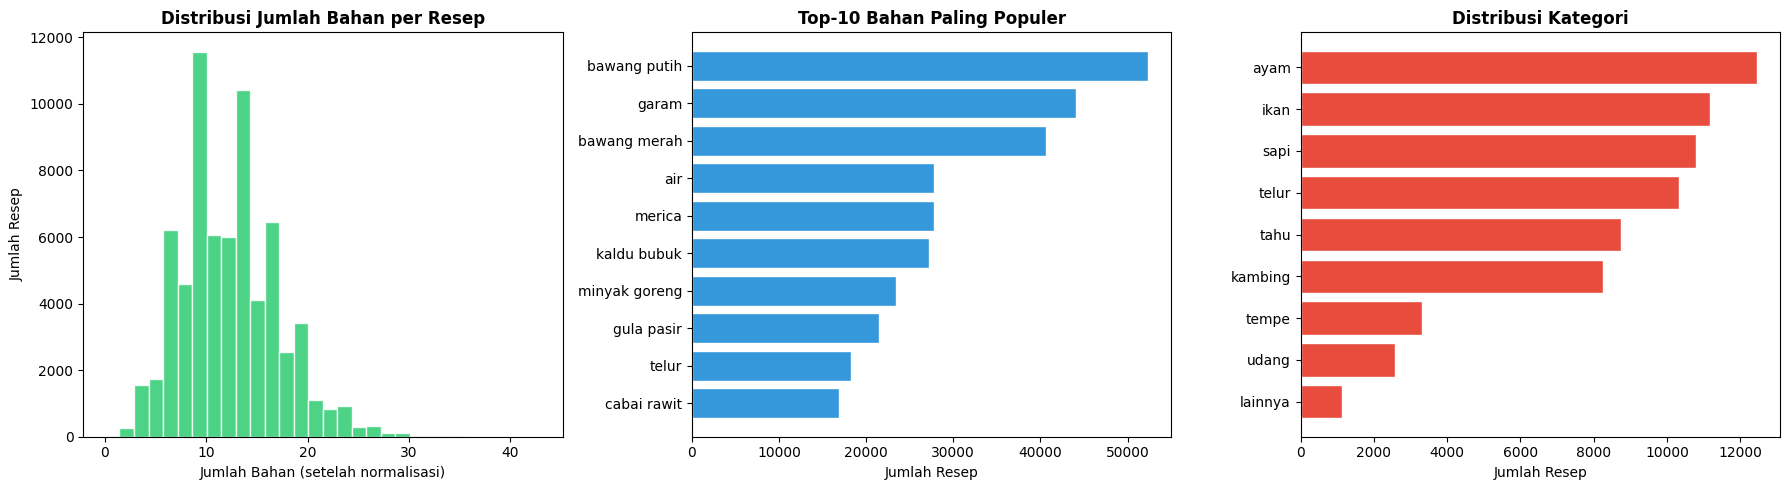

  [SAVED] Grafik analisis EDA disimpan di: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\eda_overview.png
[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.


In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6: Corpus Preprocessing Execution & EXPLORATORY DATA ANALYSIS (EDA)
# ═══════════════════════════════════════════════════════════════════════════════

print("[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...")

all_sets = []
core_sets = []
ir_token_sets = []
ir_texts = []

raw_lists = df_all["ingredients_raw_list"].tolist()
for ingr_raw in tqdm(raw_lists, total=len(raw_lists), desc="Parsing bahan"):
    result = PARSER.extract_ingredients_from_recipe(ingr_raw)
    all_sets.append(result["ingredients_all_set"])
    core_sets.append(result["ingredients_core_set"])
    ir_token_sets.append(result["ingredients_ir_tokens"])
    ir_texts.append(result["ingredients_ir_text"])

df_all["ingredients_all_set"] = all_sets
df_all["ingredients_core_set"] = core_sets
df_all["ingredients_ir_tokens"] = ir_token_sets
df_all["ingredients_ir_text"] = ir_texts

# Also create title IR text
df_all["title_ir_text"] = df_all["title_clean"].apply(
    lambda t: re.sub(r'[^a-z\s]', '', t.lower()).strip() if isinstance(t, str) else ""
)

print(f"\n  [STATS] Preprocessing selesai untuk {len(df_all)} resep.")

# ── Quick EDA ────────────────────────────────────────────────────────────────
print("\n" + "─" * 60)
print("  [EDA] EXPLORATORY DATA ANALYSIS (EDA)")
print("─" * 60)

# Distribution of ingredient counts
ingr_counts = df_all["ingredients_all_set"].apply(len)
print(f"\n  Jumlah bahan per resep:")
print(f"    Mean   : {ingr_counts.mean():.1f}")
print(f"    Median : {ingr_counts.median():.1f}")
print(f"    Min    : {ingr_counts.min()}")
print(f"    Max    : {ingr_counts.max()}")

# Top-20 most popular ingredients
all_ingr_counter = Counter()
for s in df_all["ingredients_all_set"]:
    all_ingr_counter.update(s)

print(f"\n  Top-20 Bahan Paling Populer:")
for i, (ingr, cnt) in enumerate(all_ingr_counter.most_common(20), 1):
    print(f"    {i:>2}. {ingr:<25s} : {cnt:>5} resep")

# Category distribution
print(f"\n  Distribusi Kategori:")
for cat, cnt in df_all["main_category"].value_counts().items():
    print(f"    {cat:<12s}: {cnt:>5}")

# Source distribution
print(f"\n  Distribusi Sumber:")
for src, cnt in df_all["source"].value_counts().items():
    print(f"    {src:<20s}: {cnt:>5}")

# Example: raw vs IR representation
print(f"\n  Contoh Representasi Raw vs IR:")
sample = df_all.iloc[0]
print(f"    Judul    : {sample['title_clean']}")
print(f"    Raw[0:3] : {sample['ingredients_raw_list'][:3]}")
print(f"    IR text  : {sample['ingredients_ir_text'][:120]}...")

# ── Visualisasi EDA ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi jumlah bahan
axes[0].hist(ingr_counts, bins=30, color="#2ecc71", edgecolor="white", alpha=0.85)
axes[0].set_title("Distribusi Jumlah Bahan per Resep", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Bahan (setelah normalisasi)")
axes[0].set_ylabel("Jumlah Resep")

# 2. Top-10 bahan
top10 = all_ingr_counter.most_common(10)
axes[1].barh([x[0] for x in top10][::-1], [x[1] for x in top10][::-1], color="#3498db", edgecolor="white")
axes[1].set_title("Top-10 Bahan Paling Populer", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Resep")

# 3. Kategori
cat_counts = df_all["main_category"].value_counts()
axes[2].barh(cat_counts.index[::-1], cat_counts.values[::-1], color="#e74c3c", edgecolor="white")
axes[2].set_title("Distribusi Kategori", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Jumlah Resep")

plt.tight_layout()
eda_path = ENV.ARTIFACT_DIR / "eda_overview.png"
plt.savefig(eda_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"  [SAVED] Grafik analisis EDA disimpan di: {eda_path}")
print("[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.")

In [7]:
# ==============================================================================
# CELL 7: Pemodelan Information Retrieval (Set-Overlap, TF-IDF, BM25, SisaRasa Hybrid)
# ==============================================================================

from abc import ABC, abstractmethod
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import numpy as np


def _identity_token_func(x):
    """Fungsi identitas tingkat modul agar CountVectorizer dapat diserialisasi via pickle."""
    return x


class BaseRetriever(ABC):
    name: str = "Base"

    @abstractmethod
    def index(self, corpus_df: pd.DataFrame):
        pass

    @abstractmethod
    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        """Return list of (doc_id, score) sorted by score desc."""
        pass


# -- Model 1: Set-Overlap / Jaccard Baseline -----------------------------------

class SetOverlapRetriever(BaseRetriever):
    name = "Set-Overlap"

    def __init__(self, parser: IndonesianIngredientParser):
        self.parser = parser
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_lengths = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_lengths = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        q_vec = self.vectorizer.transform([list(q_core)])
        intersections = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()
        q_len = len(q_core)
        unions = self.doc_lengths + q_len - intersections

        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersections / unions, 0.0)

        top_indices = np.argsort(jaccard)[::-1][:top_k]
        return [(self.doc_ids[i], float(jaccard[i])) for i in top_indices if jaccard[i] > 0]


# -- Model 2: TF-IDF + Cosine Similarity Baseline -----------------------------

class TfidfCosineRetriever(BaseRetriever):
    name = "TF-IDF Cosine"

    def __init__(self, parser: IndonesianIngredientParser, w_ingr: float = 0.70, w_title: float = 0.30):
        self.parser = parser
        self.w_ingr = w_ingr
        self.w_title = w_title
        self.doc_ids: List[str] = []
        self.vectorizer_ingr = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.vectorizer_title = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.tfidf_ingr = None
        self.tfidf_title = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        ingr_texts = corpus_df["ingredients_ir_text"].fillna("").tolist()
        title_texts = corpus_df["title_ir_text"].fillna("").tolist()
        self.tfidf_ingr = self.vectorizer_ingr.fit_transform(ingr_texts)
        self.tfidf_title = self.vectorizer_title.fit_transform(title_texts)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip():
            return []

        q_vec_ingr = self.vectorizer_ingr.transform([q_ir_text])
        sim_ingr = cosine_similarity(q_vec_ingr, self.tfidf_ingr).flatten()

        q_vec_title = self.vectorizer_title.transform([q_ir_text])
        sim_title = cosine_similarity(q_vec_title, self.tfidf_title).flatten()

        scores = self.w_ingr * sim_ingr + self.w_title * sim_title
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip():
            return np.zeros(len(self.doc_ids))
        q_vec_ingr = self.vectorizer_ingr.transform([q_ir_text])
        sim_ingr = cosine_similarity(q_vec_ingr, self.tfidf_ingr).flatten()
        q_vec_title = self.vectorizer_title.transform([q_ir_text])
        sim_title = cosine_similarity(q_vec_title, self.tfidf_title).flatten()
        return self.w_ingr * sim_ingr + self.w_title * sim_title


# -- Model 3: Okapi BM25 (Vectorized Sparse Matrix) ---------------------------

class BM25Retriever(BaseRetriever):
    name = "BM25"

    def __init__(self, parser: IndonesianIngredientParser, k1: float = 1.2, b: float = 0.4):
        self.parser = parser
        self.k1 = k1
        self.b = b
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.bm25_matrix: Optional[csr_matrix] = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        texts = corpus_df["ingredients_ir_text"].fillna("").tolist()

        self.vectorizer = CountVectorizer(
            token_pattern=r"(?u)\b\w+\b",
            lowercase=False
        )
        tf_matrix = self.vectorizer.fit_transform(texts)
        N, V = tf_matrix.shape

        doc_len = np.array(tf_matrix.sum(axis=1)).flatten()
        avgdl = float(doc_len.mean()) if N > 0 else 1.0

        # Document frequency df
        df = np.bincount(tf_matrix.indices, minlength=V)

        # Okapi BM25 IDF dengan smoothing +1.0
        idf = np.log((N - df + 0.5) / (df + 0.5) + 1.0)

        # Precompute bobot BM25 sparse matrix
        row_indices = np.repeat(np.arange(N), np.diff(tf_matrix.indptr))
        tf_vals = tf_matrix.data
        len_norm = 1.0 - self.b + self.b * (doc_len / (avgdl + 1e-9))
        denom = tf_vals + self.k1 * len_norm[row_indices]
        bm25_data = (tf_vals * (self.k1 + 1.0) / denom) * idf[tf_matrix.indices]

        self.bm25_matrix = csr_matrix((bm25_data, tf_matrix.indices, tf_matrix.indptr), shape=tf_matrix.shape)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        scores = self.get_scores_array(query_str)
        if scores.size == 0 or np.all(scores == 0):
            return []
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid via perkalian matriks sparse."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip() or self.bm25_matrix is None:
            return np.zeros(len(self.doc_ids))

        q_vec = self.vectorizer.transform([q_ir_text])
        if q_vec.nnz == 0:
            return np.zeros(len(self.doc_ids))

        scores = np.array(self.bm25_matrix.dot(q_vec.T).toarray()).ravel()
        return scores


# -- Model 4: SisaRasa Hybrid Culinary Ranking (Proposed Method) ---------------

class SisaRasaHybridRetriever(BaseRetriever):
    name = "SisaRasa Hybrid"

    MAIN_PROTEINS = frozenset({
        "ayam", "daging sapi", "daging kambing", "ikan", "udang",
        "cumi", "telur", "tahu", "tempe",
    })

    def __init__(self, parser: IndonesianIngredientParser,
                 bm25_retriever: BM25Retriever,
                 tfidf_retriever: TfidfCosineRetriever,
                 w1: float = 0.10, w2: float = 0.05, w3: float = 0.20,
                 w4: float = 0.20, w_jaccard: float = 0.35,
                 w5: float = 0.10, w_prot: float = 0.25):
        self.parser = parser
        self.bm25_retriever = bm25_retriever
        self.tfidf_retriever = tfidf_retriever
        self.w1 = w1
        self.w2 = w2
        self.w3 = w3
        self.w4 = w4
        self.w_jaccard = w_jaccard
        self.w5 = w5
        self.w_prot = w_prot
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_core_len = None
        self.protein_vectorizer: Optional[CountVectorizer] = None
        self.doc_protein_matrix = None
        self.doc_has_protein = None
        self.epsilon = 1e-9

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]

        # 1. Matriks biner sparse seluruh bahan inti
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_core_len = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

        # 2. Matriks biner sparse khusus Protein Utama
        doc_proteins = [[p for p in s if p in self.MAIN_PROTEINS] for s in corpus_df["ingredients_core_set"]]
        self.protein_vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_protein_matrix = self.protein_vectorizer.fit_transform(doc_proteins)
        self.doc_has_protein = (np.array(self.doc_protein_matrix.sum(axis=1)).flatten() > 0)

    def _min_max_normalize(self, arr: np.ndarray) -> np.ndarray:
        mn, mx = arr.min(), arr.max()
        if mx - mn < 1e-12:
            return np.zeros_like(arr)
        return (arr - mn) / (mx - mn)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        n = len(self.doc_ids)

        # 1. Skor probabilistik leksikal BM25 (ternormalisasi)
        bm25_raw = self.bm25_retriever.get_scores_array(query_str)
        bm25_norm = self._min_max_normalize(bm25_raw)

        # 2. Skor kecocokan vektor TF-IDF (ternormalisasi)
        tfidf_raw = self.tfidf_retriever.get_scores_array(query_str)
        tfidf_norm = self._min_max_normalize(tfidf_raw)

        # 3. Vektorisasi Set Operations via Perkalian Matriks Sparse
        q_vec = self.vectorizer.transform([list(q_core)])
        intersection = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()

        q_core_len = len(q_core)
        # Smoothing pada penyebut core_coverage untuk meredam resep terlalu pendek (doc_core_len < 2)
        denom_len = np.maximum(self.doc_core_len, 2.0 if q_core_len >= 2 else 1.0)
        core_coverage = intersection / (denom_len + self.epsilon)
        query_util = intersection / (q_core_len + self.epsilon)

        unions = self.doc_core_len + q_core_len - intersection
        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersection / unions, 0.0)

        missing = np.maximum(0, self.doc_core_len - intersection - 2)
        missing_penalty = missing / (self.doc_core_len + 3)

        # 4. Main Protein Alignment
        q_proteins = q_core & self.MAIN_PROTEINS
        protein_alignment = np.zeros(n)
        if q_proteins:
            q_prot_vec = self.protein_vectorizer.transform([list(q_proteins)])
            protein_inter = np.array(self.doc_protein_matrix.dot(q_prot_vec.T).toarray()).flatten()
            protein_alignment[protein_inter > 0] = 1.0
            protein_alignment[(protein_inter == 0) & self.doc_has_protein] = -0.5

        # 5. Masking Penalti jika bahan cocok < 2 saat query memiliki >= 2 bahan inti
        min_match_mask = (intersection >= 2) if q_core_len >= 2 else (intersection >= 1)

        # 6. Formula Skor Hybrid Terkalibrasi
        scores = (self.w1 * bm25_norm
                  + self.w2 * tfidf_norm
                  + self.w3 * core_coverage
                  + self.w4 * query_util
                  + self.w_jaccard * jaccard
                  - self.w5 * missing_penalty
                  + self.w_prot * protein_alignment)
        scores = np.where(min_match_mask, scores, scores * 0.25)

        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]


print("[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.")


[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8: Indexing Korpus & Pengukuran Resource (Waktu & Penggunaan Memori)
# ═══════════════════════════════════════════════════════════════════════════════

import sys

def measure_size_mb(obj) -> float:
    """Rough memory estimate in MB."""
    try:
        return sys.getsizeof(pickle.dumps(obj)) / (1024 * 1024)
    except Exception:
        return 0.0


print("[INDEX] Membangun indeks 4 model retrieval ...\n")

# Instantiate models
model_setoverlap = SetOverlapRetriever(PARSER)
model_tfidf = TfidfCosineRetriever(PARSER)
model_bm25 = BM25Retriever(PARSER, k1=1.2, b=0.4)
model_hybrid = SisaRasaHybridRetriever(PARSER, model_bm25, model_tfidf)

models = {
    "Set-Overlap": model_setoverlap,
    "TF-IDF Cosine": model_tfidf,
    "BM25": model_bm25,
    "SisaRasa Hybrid": model_hybrid,
}

index_stats = []
for name, model in models.items():
    t0 = time.perf_counter()
    model.index(df_all)
    t1 = time.perf_counter()
    mem = measure_size_mb(model)
    index_stats.append({"Model": name, "Index Time (s)": round(t1 - t0, 3), "Size (MB)": round(mem, 2)})
    print(f"  [OK] {name:<20s}: {t1-t0:.3f}s, ~{mem:.1f} MB")

df_index_stats = pd.DataFrame(index_stats)
print(f"\n{df_index_stats.to_string(index=False)}")

# Quick sanity check
test_query = "ayam, bawang merah, bawang putih, kecap manis"
print(f"\n  [QUERY] SANITY CHECK QUERY: '{test_query}'")
for name, model in models.items():
    results = model.retrieve(test_query, top_k=3)
    if results:
        top_title = df_all.loc[df_all["doc_id"] == results[0][0], "title_clean"].iloc[0]
        print(f"    {name:<20s} → #{1}: {top_title} (skor: {results[0][1]:.4f})")
    else:
        print(f"    {name:<20s} → (no results)")

print("[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.")

[INDEX] Membangun indeks 4 model retrieval ...

  [OK] Set-Overlap         : 1.159s, ~10.2 MB
  [OK] TF-IDF Cosine       : 2.128s, ~27.7 MB
  [OK] BM25                : 2.129s, ~23.8 MB
  [OK] SisaRasa Hybrid     : 1.400s, ~61.7 MB

          Model  Index Time (s)  Size (MB)
    Set-Overlap           1.159      10.16
  TF-IDF Cosine           2.128      27.68
           BM25           2.129      23.77
SisaRasa Hybrid           1.400      61.68

  [QUERY] SANITY CHECK QUERY: 'ayam, bawang merah, bawang putih, kecap manis'
    Set-Overlap          → #1: Ayam Kecap (skor: 1.0000)
    TF-IDF Cosine        → #1: Ayam Kecap (skor: 0.6946)
    BM25                 → #1: Semur Ayam Bumbu Merah (skor: 7.6178)
    SisaRasa Hybrid      → #1: Ayam Kecap (skor: 1.1482)
[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.


In [9]:
# ==============================================================================
# CELL 9: Generator Stratified Benchmark Queries (Skenario A-D) & Automated Qrels
# ==============================================================================

class BenchmarkQueryGenerator:
    """Pembangkit query evaluasi stratified berdasarkan 4 skenario."""

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser, seed: int = 42):
        self.corpus = corpus_df
        self.parser = parser
        self.rng = np.random.RandomState(seed)

    def _sample_ingredients_from_corpus(self, n_ingredients: int, category: Optional[str] = None) -> str:
        """Sample bahan dari resep nyata di korpus."""
        if category:
            pool = self.corpus[self.corpus["main_category"] == category]
            if pool.empty:
                pool = self.corpus
        else:
            pool = self.corpus

        idx = self.rng.randint(0, len(pool))
        recipe = pool.iloc[idx]
        core = sorted(recipe["ingredients_core_set"])
        if len(core) < n_ingredients:
            selected = core
        else:
            self.rng.shuffle(core)
            selected = core[:n_ingredients]
        return ", ".join(selected)

    def generate_scenario_a(self, n: int = 12) -> List[Dict]:
        """Skenario A: Sisa Kulkas Minimalis (2-3 bahan inti)."""
        handcrafted = [
            "telur, tahu, kecap manis",
            "tempe, cabai rawit, bawang putih",
            "ayam, bawang merah, garam",
            "tahu, bayam, bawang putih",
            "telur, wortel, bawang merah",
            "udang, bawang putih, cabai",
            "tempe, kecap manis, cabai rawit",
            "telur, kangkung",
            "tahu, cabai merah, tomat",
            "ikan, kunyit, serai",
            "daging sapi, bawang bombay, merica",
            "ayam, jahe, bawang putih",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"A{i+1:02d}", "scenario": "A", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(2, 4))
            queries.append({"query_id": f"A{len(queries)+1:02d}", "scenario": "A", "query_text": q})
        return queries

    def generate_scenario_b(self, n: int = 12) -> List[Dict]:
        """Skenario B: Masak Harian Standar (4-6 bahan inti)."""
        handcrafted = [
            "ayam, bawang merah, bawang putih, kecap manis, merica, kentang",
            "tempe, cabai merah, bawang merah, bawang putih, tomat, kecap manis",
            "udang, bawang putih, mentimun, cabai rawit, serai, santan",
            "telur, wortel, kubis, bawang putih, kecap manis, saus tiram",
            "tahu, jamur, wortel, bawang putih, saus tiram, daun bawang",
            "daging sapi, bawang bombay, wortel, kentang, tomat, seledri",
            "ikan, kunyit, cabai merah, bawang merah, tomat, serai",
            "ayam, santan, serai, daun jeruk, lengkuas, cabai",
            "tempe, buncis, bawang merah, bawang putih, cabai hijau, terasi",
            "telur, bayam, wortel, bawang putih, bawang merah, jagung",
            "tahu, udang, tauge, kecap manis, bawang putih, saus tiram",
            "daging sapi, kentang, wortel, bawang bombay, tomat, seledri",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"B{i+1:02d}", "scenario": "B", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(4, 7))
            queries.append({"query_id": f"B{len(queries)+1:02d}", "scenario": "B", "query_text": q})
        return queries

    def generate_scenario_c(self, n: int = 12) -> List[Dict]:
        """Skenario C: Kombinasi Bahan Lengkap (7-10 bahan inti)."""
        handcrafted = [
            "ayam, santan, serai, lengkuas, daun jeruk, kunyit, cabai merah, bawang merah, bawang putih, kemiri",
            "daging sapi, santan, serai, lengkuas, kunyit, jahe, cabai merah, bawang merah, bawang putih, kelapa",
            "ikan, kunyit, cabai merah, bawang merah, bawang putih, tomat, serai, daun kunyit, kemiri, asam jawa",
            "ayam, kentang, wortel, bawang bombay, bawang putih, tomat, seledri, daun salam, merica, pala",
            "udang, santan, cabai merah, bawang merah, bawang putih, kunyit, serai, lengkuas, daun jeruk",
            "tempe, tahu, cabai merah, bawang merah, bawang putih, tomat, terasi, kecap manis, daun jeruk, serai",
            "daging kambing, santan, serai, lengkuas, jahe, kunyit, cabai, ketumbar, jintan, kayu manis",
            "ayam, bawang merah, bawang putih, jahe, kunyit, ketumbar, kemiri, santan, serai, daun salam",
            "ikan, bawang merah, bawang putih, cabai merah, cabai rawit, tomat, terasi, serai, lengkuas, kunyit",
            "telur, santan, bawang merah, bawang putih, cabai, kunyit, daun jeruk, serai, lengkuas",
            "daging sapi, bawang merah, bawang putih, cabai, jahe, serai, kecap manis, lengkuas, daun salam, merica",
            "udang, cabai merah, bawang merah, bawang putih, tomat, terasi, lengkuas, serai, daun jeruk, kunyit",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"C{i+1:02d}", "scenario": "C", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(7, 11))
            queries.append({"query_id": f"C{len(queries)+1:02d}", "scenario": "C", "query_text": q})
        return queries

    def generate_scenario_d(self, n: int = 12) -> List[Dict]:
        """Skenario D: Noisy / Colloquial User Input."""
        handcrafted = [
            "2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
            "telor 3 btr, terigu 200gr, mentega, gula pasir, vanili",
            "1/2 kg daging sapi, 2 bh kentang, bw merah, bw putih, kecap bango",
            "tempe 1 papan, lombok rawit, bamer 5 siung, baput 3 siung, santen, gula jawa",
            "udang kupas 250gr, 3 siung baput, cabe ijo, saori, minyak sayur",
            "3 potong tahu putih, telor 2 butir, terigu, bawang pth, cabe rawit",
            "1 ekor ikan nila, kunir, laos, sereh, daun salam, cabe merah besar",
            "dada ayam fillet 500g, bw bombai, saus tomat, kecap, merica bubuk",
            "toge 1 ikat, tahu 2 buah, bamer, baput, kecap, cabe rawit",
            "4 butir telor, sledri, daun prei, royco, minyak, garam secukupnya",
            "kambing 1 kg, santen 500 ml, laos, sereh, jinten, kayu manis, pekak",
            "ikan tongkol 3 ptg, asem jawa, cabe, bamer, tomat, terasi, gula merah",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"D{i+1:02d}", "scenario": "D", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(3, 8))
            queries.append({"query_id": f"D{len(queries)+1:02d}", "scenario": "D", "query_text": q})
        return queries

    def generate_all(self, n_per_scenario: int = 12) -> List[Dict]:
        all_queries = []
        all_queries.extend(self.generate_scenario_a(n_per_scenario))
        all_queries.extend(self.generate_scenario_b(n_per_scenario))
        all_queries.extend(self.generate_scenario_c(n_per_scenario))
        all_queries.extend(self.generate_scenario_d(n_per_scenario))
        return all_queries


# -- Reproducible pseudo-qrels protocol ----------------------------------------

EVALUATION_PROTOCOL = {
    "seed": 42,
    "proxy_qrel_version": "proxy_v2",
    "binary_relevance_threshold": 2,
    "zero_denominator_policy": "score zero for all-query macro; eligible-only mean is null when no query is eligible",
    "aggregation": "macro means for all queries and eligible queries within each split and scenario; binary eligibility requires grade >= 2, nDCG eligibility requires IDCG > 0",
    "split_ratio": {"dev": 0.75, "test": 0.25},
    "split_unit": "canonical reference ingredient family",
    "split_limit": "exact family grouping only; inspected synthetic queries are not an untouched holdout",
    "proxy_assessment_universe": "all df_all doc_id values",
    "proxy_qrel_input": "clean reference ingredients; retrieval receives the original query",
    "noisy_scenario": "synthetic quantities and selected culinary aliases, not typo correction",
    "known_item_label": "pemulihan resep sumber berdasarkan bahan",
    "known_item_relevance": "measure recovery of the declared source recipe only; other recipes are not judged irrelevant",
    "known_item_limit": "sampled ingredient subsets may match many recipes and need not identify a unique target",
    "model_feature_limit": "TF-IDF also uses titles; model differences are not algorithm-only",
    "latency_limit": "one retrieval call per query without warm-up; descriptive only",
    "coverage_formula": "shared_core / document_core_count when both core sets are nonempty",
    "query_utility_formula": "shared_core / reference_query_core_count when both core sets are nonempty",
    "metric_definitions": {
        "P@k": "relevant returned in top k / k",
        "R@k": "relevant returned in top k / all relevant in proxy assessment universe",
        "AP@10": "sum of precision at relevant ranks in top 10 / min(10, total relevant)",
        "nDCG@k": "gain 2**grade - 1 with log2(rank + 1) discount; ideal from all qrels",
        "RR@10": "reciprocal rank of first grade >= 2 within top 10, else zero",
    },
    "grade_rules": {
        "3": "protein match when query has protein; core coverage >= 0.65; query utility >= 0.60",
        "2": "protein match when applicable; >= 2 shared core ingredients; core coverage >= 0.45; query utility >= 0.50",
        "1": ">= 2 shared core ingredients and core coverage >= 0.30",
        "0": "all remaining pairs; omitted from sparse qrels inside the declared corpus universe",
    },
    "parser_dependency": "IndonesianIngredientParser.parse_query core ingredient output",
    "hybrid_feature_overlap": ["core coverage", "query utility", "protein alignment"],
    "limitations": (
        "Heuristic ingredient rubric overlaps Hybrid core coverage, query utility, "
        "and protein alignment; proxy scores measure rubric agreement, not human relevance. "
        "Corpus-derived synthetic queries do not establish real-user performance."
    ),
}

def canonical_query_family(query_text: str, parser: IndonesianIngredientParser) -> str:
    """Stable family key from a tuple of sorted parsed core ingredients."""
    core = tuple(sorted(parser.parse_query(query_text)["ingredients_core_set"]))
    return json.dumps(core, ensure_ascii=False, separators=(",", ":"))


def split_query_families(queries: List[Dict], seed: int = 42,
                         forced_dev_families: Set[str] = None) -> Tuple[List[Dict], Dict[str, str]]:
    """Assign whole ingredient families to deterministic scenario-stratified splits."""
    family_scenarios = {}
    for query in queries:
        family_scenarios.setdefault(query["family_id"], set()).add(query["scenario"])

    strata = {}
    for family_id, scenarios in family_scenarios.items():
        strata.setdefault(tuple(sorted(scenarios)), []).append(family_id)

    rng = np.random.RandomState(seed)
    forced_dev_families = set(forced_dev_families or ())
    assignments = {}
    for stratum in sorted(strata):
        all_family_ids = sorted(strata[stratum])
        family_ids = [family_id for family_id in all_family_ids if family_id not in forced_dev_families]
        assignments.update({family_id: "dev" for family_id in all_family_ids if family_id in forced_dev_families})
        shuffled = list(rng.permutation(family_ids))
        test_count = int(round(len(family_ids) * 0.25)) if len(family_ids) > 1 else 0
        if len(family_ids) > 1:
            test_count = max(1, min(len(family_ids) - 1, test_count))
        test_families = set(shuffled[:test_count])
        assignments.update({
            family_id: ("test" if family_id in test_families else "dev")
            for family_id in family_ids
        })

    split_queries = [{**query, "split": assignments[query["family_id"]]} for query in queries]
    return split_queries, assignments


def generate_sampled_queries(generator: BenchmarkQueryGenerator, n_per_scenario: int = 12) -> List[Dict]:
    """Sample stable reference ingredients and add controlled noise only to D."""
    bounds = {"A": (2, 4), "B": (4, 7), "C": (7, 11), "D": (3, 8)}
    aliases = {
        "bawang merah": "bamer", "bawang putih": "baput", "cabai": "cabe",
        "telur": "telor", "santan": "santen", "serai": "sereh",
    }
    queries = []
    for scenario, (low, high) in bounds.items():
        for index in range(n_per_scenario):
            requested_count = int(generator.rng.randint(low, high))
            fallback = None
            for _ in range(50):
                reference = generator._sample_ingredients_from_corpus(requested_count)
                ingredients = reference.split(", ") if reference else []
                expected_core = set(ingredients)
                if not expected_core or generator.parser.parse_query(reference)["ingredients_core_set"] != expected_core:
                    continue
                if fallback is None:
                    fallback = (reference, ingredients, expected_core)
                if low <= len(expected_core) < high:
                    break
            else:
                if fallback is None:
                    raise ValueError(f"Cannot sample a stable reference query for scenario {scenario}")
                reference, ingredients, expected_core = fallback
            query_text = reference
            noise_types = []
            if scenario == "D":
                query_text = ", ".join(
                    f"{position} buah {aliases.get(ingredient, ingredient)}"
                    for position, ingredient in enumerate(ingredients, start=1)
                )
                noise_types = ["quantity"]
                if any(ingredient in aliases for ingredient in ingredients):
                    noise_types.append("culinary_alias")
            observed_core = set(generator.parser.parse_query(query_text)["ingredients_core_set"])
            queries.append({
                "query_id": f"{scenario}N{index + 1:02d}",
                "scenario": scenario,
                "query_text": query_text,
                "reference_query_text": reference,
                "expected_core_ingredients": sorted(expected_core),
                "observed_core_ingredients": sorted(observed_core),
                "normalization_exact_match": observed_core == expected_core,
                "requested_ingredient_count": requested_count,
                "scenario_range_valid": low <= len(expected_core) < high,
                "noise_types": noise_types,
                "source": "corpus_sampled_noisy" if noise_types else "corpus_sampled",
            })
    return queries


class QrelGenerator:
    """Sparse pseudo-qrels graded by the explicit proxy_v2 rubric."""

    MAIN_PROTEIN_KEYWORDS = frozenset({
        "ayam", "daging sapi", "daging kambing", "ikan", "udang",
        "cumi", "telur", "tahu", "tempe",
    })
    RUBRIC_VERSION = "proxy_v2"

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser):
        self.corpus = corpus_df
        self.parser = parser
        doc_ids = corpus_df["doc_id"].tolist()
        if len(doc_ids) != len(set(doc_ids)):
            raise ValueError("Assessment corpus contains duplicate document IDs")
        self.assessment_doc_ids = sorted(doc_ids)
        self._assessment_doc_id_set = set(doc_ids)
        self._doc_core_sets = [set(values) for values in corpus_df["ingredients_core_set"].tolist()]
        self._doc_proteins = [values & self.MAIN_PROTEIN_KEYWORDS for values in self._doc_core_sets]

    def validate_assessment_ids(self, doc_ids: List[str]) -> None:
        unknown = set(doc_ids) - self._assessment_doc_id_set
        if unknown:
            raise ValueError(f"Retrieved document IDs outside assessment universe: {sorted(unknown)}")

    def grade_query(self, query_text: str) -> Dict[str, int]:
        """Parse once, grade the full corpus, and return sorted nonzero judgments."""
        q_core = self.parser.parse_query(query_text)["ingredients_core_set"]
        q_proteins = q_core & self.MAIN_PROTEIN_KEYWORDS
        grades = {}
        for doc_id, d_core, d_proteins in zip(
            self.corpus["doc_id"].tolist(), self._doc_core_sets, self._doc_proteins
        ):
            intersection = q_core & d_core
            inter_len = len(intersection)
            grade = 0
            if q_core and d_core:
                core_coverage = inter_len / len(d_core)
                query_util = inter_len / len(q_core)
                protein_match = bool(q_proteins & d_proteins) if q_proteins else True
                if protein_match and core_coverage >= 0.65 and query_util >= 0.60:
                    grade = 3
                elif protein_match and core_coverage >= 0.45 and inter_len >= 2 and query_util >= 0.50:
                    grade = 2
                elif inter_len >= 2 and core_coverage >= 0.30:
                    grade = 1
            if grade:
                grades[doc_id] = grade
        return dict(sorted(grades.items()))

    def grade_known_item(self, target_doc_id: str, target_family_ids: Set[str]) -> Dict[str, int]:
        """Mark declared source targets, not general recipe relevance."""
        if target_doc_id not in self._assessment_doc_id_set:
            raise ValueError(f"Unknown known-item target: {target_doc_id}")
        if target_doc_id not in target_family_ids or not target_family_ids <= self._assessment_doc_id_set:
            raise ValueError("Known-item family must contain target and only corpus document IDs")
        return {doc_id: 2 for doc_id in sorted(target_family_ids)}


def _check_proxy_v2():
    class FixtureParser:
        def parse_query(self, query_text):
            return {"ingredients_core_set": set(query_text.split(",")) if query_text else set()}

    corpus = pd.DataFrame([
        {"doc_id": "boundary", "ingredients_core_set": {"a", "b", "x"}},
        {"doc_id": "empty", "ingredients_core_set": set()},
    ])
    generator = QrelGenerator(corpus, FixtureParser())
    actual = generator.grade_query("a,b,c,d")
    assert actual == {"boundary": 2}, f"Boundary grade: {actual}"
    assert generator.grade_query("") == {}
    assert generator.RUBRIC_VERSION == "proxy_v2"


_check_proxy_v2()


# -- Preserve historical queries as retrospective data -------------------------
print("[EVAL] Menjaga 48 kueri lama sebagai data retrospektif ...")
legacy_query_gen = BenchmarkQueryGenerator(df_all, PARSER, seed=EVALUATION_PROTOCOL["seed"])
legacy_proxy_queries = legacy_query_gen.generate_all(n_per_scenario=12)
for query in legacy_proxy_queries:
    query["family_id"] = canonical_query_family(query["query_text"], PARSER)
    query["split"] = "retrospective_dev"
    query["evaluation_status"] = "legacy_descriptive"

# -- Generate fresh proxy and known-item query families ------------------------
print("[EVAL] Membangkitkan query evaluasi baru ...")
fresh_query_gen = BenchmarkQueryGenerator(df_all, PARSER, seed=EVALUATION_PROTOCOL["seed"])
proxy_queries = generate_sampled_queries(fresh_query_gen, n_per_scenario=12)
for query in proxy_queries:
    query["family_id"] = canonical_query_family(query["reference_query_text"], PARSER)
known_item_candidates = sorted(
    (tuple(sorted(row.ingredients_core_set)), row.doc_id)
    for row in df_all[["doc_id", "ingredients_core_set"]].itertuples(index=False)
    if len(row.ingredients_core_set) >= 2
)
known_item_rng = np.random.RandomState(EVALUATION_PROTOCOL["seed"])
known_item_queries = []
for candidate_index in known_item_rng.permutation(len(known_item_candidates)):
    core, target_doc_id = known_item_candidates[candidate_index]
    stable_core = [ingredient for ingredient in core
                   if PARSER.parse_query(ingredient)["ingredients_core_set"] == {ingredient}]
    if len(stable_core) < 2:
        continue
    subset = sorted(known_item_rng.choice(stable_core, size=min(3, len(stable_core)), replace=False).tolist())
    query_text = ", ".join(subset)
    if PARSER.parse_query(query_text)["ingredients_core_set"] != set(subset):
        continue
    family_id = canonical_query_family(query_text, PARSER)
    known_item_queries.append({
        "query_id": f"KI{len(known_item_queries) + 1:03d}",
        "family_id": family_id,
        "target_family_key": f"{target_doc_id}:{family_id}",
        "scenario": "known_item",
        "query_text": query_text,
        "reference_query_text": query_text,
        "expected_core_ingredients": subset,
        "observed_core_ingredients": subset,
        "normalization_exact_match": True,
        "target_doc_id": target_doc_id,
        "target_family_ids": [target_doc_id],
        "source": "corpus_target",
    })
    if len(known_item_queries) == 48:
        break
combined_queries, combined_family_splits = split_query_families(
    proxy_queries + known_item_queries,
    seed=EVALUATION_PROTOCOL["seed"],
    forced_dev_families={query["family_id"] for query in legacy_proxy_queries},
)
proxy_queries = combined_queries[:len(proxy_queries)]
known_item_queries = combined_queries[len(proxy_queries):]
proxy_splits = [
    {"query_id": query["query_id"], "family_id": query["family_id"],
     "split": query["split"], "scenario": query["scenario"], "target_doc_id": None}
    for query in proxy_queries
]
known_item_splits = [
    {"query_id": query["query_id"], "family_id": query["family_id"],
     "split": query["split"], "scenario": query["scenario"],
     "target_doc_id": query["target_doc_id"]}
    for query in known_item_queries
]

assert len(legacy_proxy_queries) == 48
assert all(query["split"] == "retrospective_dev" for query in legacy_proxy_queries)
assert {q["family_id"] for q in proxy_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in proxy_queries if q["split"] == "test"
)
assert {q["family_id"] for q in known_item_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in known_item_queries if q["split"] == "test"
)
assert {q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "test"
)
assert {q["family_id"] for q in legacy_proxy_queries}.isdisjoint(
    q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "test"
)
assert {query["scenario"] for query in proxy_queries} == {"A", "B", "C", "D"}
assert all(query["query_text"] != query["reference_query_text"] and query["noise_types"]
           for query in proxy_queries if query["scenario"] == "D")
assert all(query["target_family_ids"] == [query["target_doc_id"]] for query in known_item_queries)
print(f"  Legacy retrospective queries: {len(legacy_proxy_queries)}")
print(f"  Fresh proxy queries: {len(proxy_queries)}")
print(f"  Query pemulihan resep sumber berdasarkan bahan: {len(known_item_queries)}")
noisy_queries = [query for query in proxy_queries if query["scenario"] == "D"]
print(f"  D normalization exact matches: {sum(query['normalization_exact_match'] for query in noisy_queries)}/{len(noisy_queries)} (synthetic quantity/alias only)")
invalid_ranges = [query["query_id"] for query in proxy_queries if not query["scenario_range_valid"]]
if invalid_ranges:
    print(f"  [WARN] Scenario ingredient-count range not met: {invalid_ranges}")

# -- Build distinct full-corpus proxy qrels and known-item target qrels --------
qrel_gen = QrelGenerator(df_all, PARSER)
assert qrel_gen.RUBRIC_VERSION == EVALUATION_PROTOCOL["proxy_qrel_version"]
proxy_assessment_doc_ids = qrel_gen.assessment_doc_ids
proxy_qrels = {
    query["query_id"]: qrel_gen.grade_query(query["reference_query_text"])
    for query in proxy_queries
}
known_item_qrels = {
    query["query_id"]: qrel_gen.grade_known_item(
        query["target_doc_id"], set(query["target_family_ids"])
    )
    for query in known_item_queries
}
assert all(set(qrels) <= set(proxy_assessment_doc_ids) for qrels in proxy_qrels.values())
assert all(query["family_id"] == canonical_query_family(query["reference_query_text"], PARSER)
           for query in proxy_queries)
assert proxy_qrels[noisy_queries[0]["query_id"]] == qrel_gen.grade_query(noisy_queries[0]["reference_query_text"])
assert all(known_item_qrels[query["query_id"]] == {query["target_doc_id"]: 2}
           for query in known_item_queries)
assert set(proxy_qrels).isdisjoint(known_item_qrels)
print(f"[OK] Sparse full-corpus proxy qrels: {len(proxy_qrels)} queries")
print(f"[OK] Pemulihan resep sumber berdasarkan bahan: {len(known_item_qrels)} query")


[EVAL] Menjaga 48 kueri lama sebagai data retrospektif ...
[EVAL] Membangkitkan query evaluasi baru ...
  Legacy retrospective queries: 48
  Fresh proxy queries: 48
  Query pemulihan resep sumber berdasarkan bahan: 48
  D normalization exact matches: 12/12 (synthetic quantity/alias only)
[OK] Sparse full-corpus proxy qrels: 48 queries
[OK] Pemulihan resep sumber berdasarkan bahan: 48 query


[EVAL] Mengukur agreement pseudo-qrels dan pemulihan resep sumber berdasarkan bahan ...
  Evaluating Set-Overlap ...
  Evaluating TF-IDF Cosine ...
  Evaluating BM25 ...
  Evaluating SisaRasa Hybrid ...
[OK] Agreement proxy dan pemulihan resep sumber dievaluasi terpisah.

Proxy v2: agreement semua query dan query eligible (test split)
Eligible: grade >= 2 untuk metrik biner; IDCG > 0 untuk nDCG.
                    P@5     R@5    F1@5  nDCG@5   P@10    R@10   F1@10  nDCG@10  MAP@10  MRR@10  Latency (ms)  query_count  zero_relevant_queries  zero_idcg_queries  P@5 (eligible)  R@5 (eligible)  F1@5 (eligible)  nDCG@5 (eligible)  P@10 (eligible)  R@10 (eligible)  F1@10 (eligible)  nDCG@10 (eligible)  MAP@10 (eligible)  MRR@10 (eligible)  binary_eligible_queries  ndcg_eligible_queries
Model                                                                                                                                                                                                             

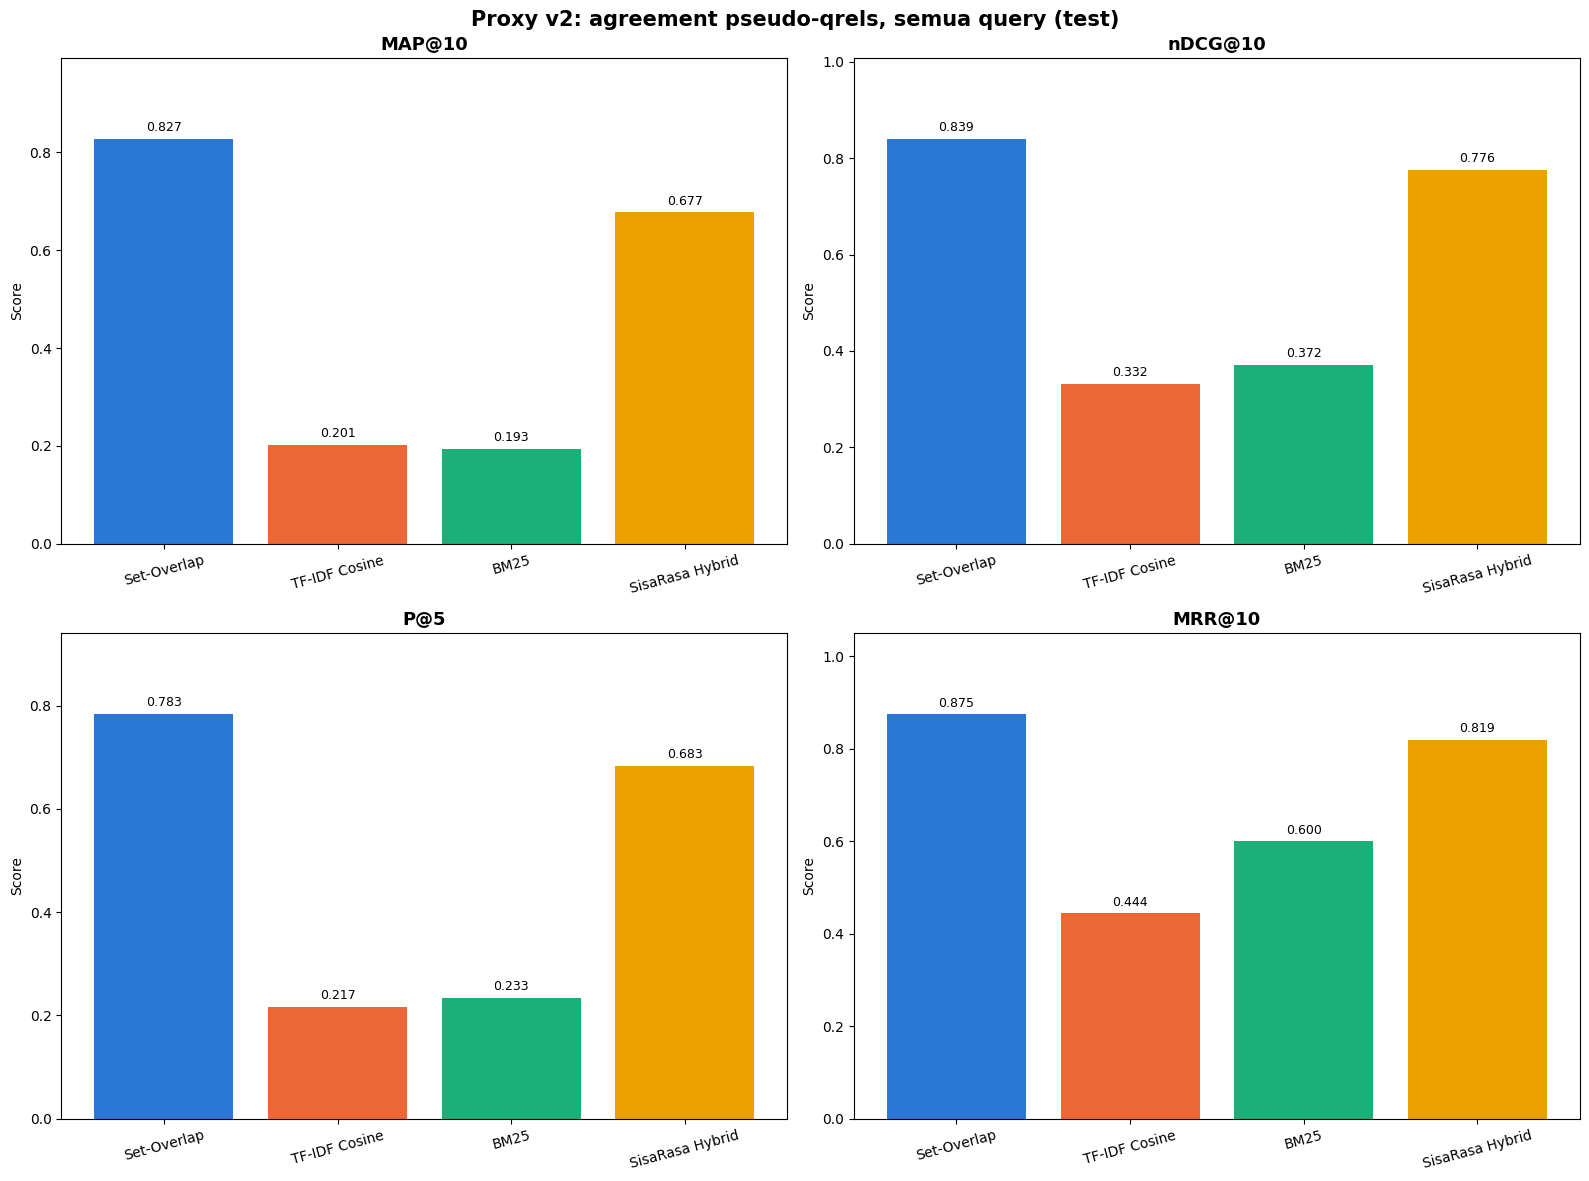

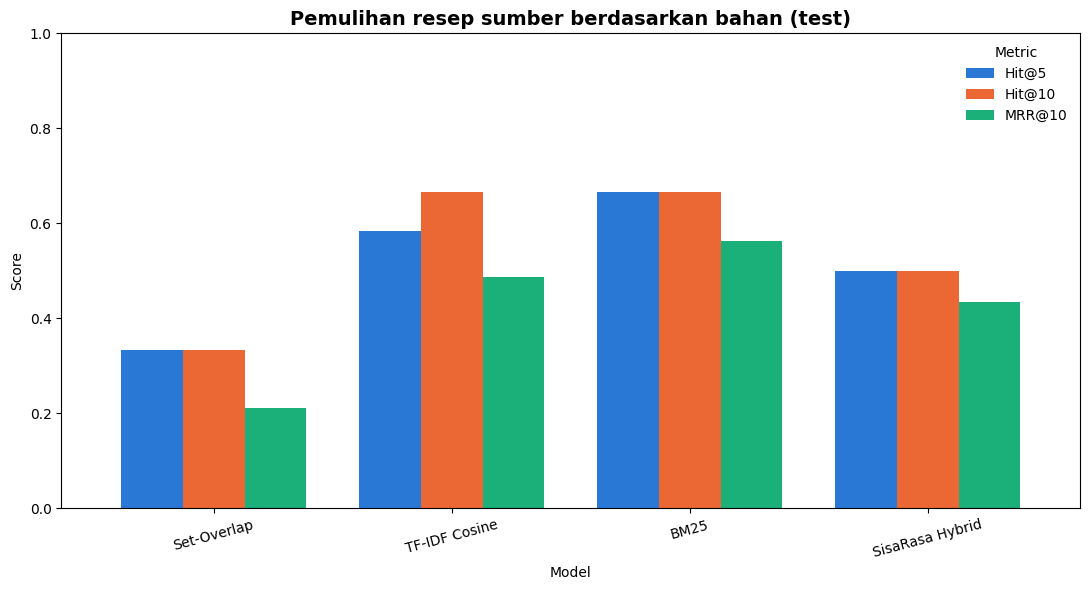

In [10]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10: Evaluasi proxy dan known-item (MRR@10)
# ═══════════════════════════════════════════════════════════════════════════════

import math
from collections import defaultdict


class IRMetricsEvaluator:
    """Evaluate pseudo-qrels agreement or source-recipe recovery, not human relevance."""

    BINARY_THRESHOLD = 2
    EVALUATOR_VERSION = "pseudo_ir_metrics_v5"

    @staticmethod
    def precision_at_k(retrieved_grades: List[int], k: int, threshold: int = 2) -> float:
        if k <= 0:
            raise ValueError("k must be positive")
        return sum(grade >= threshold for grade in retrieved_grades[:k]) / k

    @staticmethod
    def recall_at_k(retrieved_grades: List[int], k: int, total_relevant: int,
                    threshold: int = 2) -> float:
        if total_relevant <= 0:
            return 0.0
        return sum(grade >= threshold for grade in retrieved_grades[:k]) / total_relevant

    @staticmethod
    def f1_at_k(precision: float, recall: float) -> float:
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)

    @staticmethod
    def average_precision_at_k(retrieved_grades: List[int], k: int, total_relevant: int,
                               threshold: int = 2) -> float:
        if k <= 0:
            raise ValueError("k must be positive")
        denominator = min(k, total_relevant)
        if denominator <= 0:
            return 0.0
        num_relevant = 0
        precision_sum = 0.0
        for rank, grade in enumerate(retrieved_grades[:k], start=1):
            if grade >= threshold:
                num_relevant += 1
                precision_sum += num_relevant / rank
        return precision_sum / denominator

    @staticmethod
    def reciprocal_rank(retrieved_grades: List[int], threshold: int = 2) -> float:
        for rank, grade in enumerate(retrieved_grades[:10], start=1):
            if grade >= threshold:
                return 1.0 / rank
        return 0.0

    @staticmethod
    def hit_at_k(retrieved_grades: List[int], k: int, threshold: int = 2) -> float:
        return float(any(grade >= threshold for grade in retrieved_grades[:k]))

    @staticmethod
    def dcg_at_k(retrieved_grades: List[int], k: int) -> float:
        return sum((2**grade - 1) / math.log2(rank + 1)
                   for rank, grade in enumerate(retrieved_grades[:k], start=1))

    @classmethod
    def ndcg_at_k(cls, retrieved_grades: List[int], k: int, all_grades: List[int]) -> float:
        idcg = cls.dcg_at_k(sorted(all_grades, reverse=True), k)
        if idcg == 0:
            return 0.0
        return cls.dcg_at_k(retrieved_grades, k) / idcg

    def evaluate_model(self, model, queries: List[Dict], qrels: Dict[str, Dict[str, int]],
                       assessment_doc_ids: List[str], evaluation_type: str,
                       k_values: List[int] = None) -> Tuple[Dict, Dict, List[Dict]]:
        """Return overall-by-split, scenario-by-split and per-query records."""
        if not queries:
            raise ValueError("queries must be nonempty")
        if evaluation_type not in {"proxy", "known_item"}:
            raise ValueError("evaluation_type must be 'proxy' or 'known_item'")
        if not assessment_doc_ids or len(assessment_doc_ids) != len(set(assessment_doc_ids)):
            raise ValueError("assessment_doc_ids must be a nonempty unique document universe")
        k_values = [5, 10] if k_values is None else sorted(set(k_values))
        if not k_values or any(k <= 0 for k in k_values):
            raise ValueError("k_values must contain positive cutoffs")
        max_k = max(10, max(k_values))
        allowed_ids = set(assessment_doc_ids)
        records = []
        for query in queries:
            qid = query["query_id"]
            if qid not in qrels:
                raise ValueError(f"Missing qrels for query: {qid}")
            qrels_for_query = qrels[qid]
            unknown_qrels = set(qrels_for_query) - allowed_ids
            if unknown_qrels:
                raise ValueError(f"Qrels outside assessment universe: {sorted(unknown_qrels)}")
            t0 = time.perf_counter()
            retrieved = model.retrieve(query["query_text"], top_k=max_k)
            latency_ms = (time.perf_counter() - t0) * 1000
            retrieved_ids = [doc_id for doc_id, _ in retrieved]
            if len(retrieved_ids) != len(set(retrieved_ids)):
                raise ValueError("Retriever returned duplicate document IDs")
            unknown_retrieved = set(retrieved_ids) - allowed_ids
            if unknown_retrieved:
                raise ValueError(f"Retrieved IDs outside assessment universe: {sorted(unknown_retrieved)}")
            retrieved_grades = [qrels_for_query.get(doc_id, 0) for doc_id in retrieved_ids]
            total_relevant = sum(grade >= self.BINARY_THRESHOLD for grade in qrels_for_query.values())
            metrics = {}
            if evaluation_type == "proxy":
                for k in k_values:
                    precision = self.precision_at_k(retrieved_grades, k)
                    recall = self.recall_at_k(retrieved_grades, k, total_relevant)
                    metrics[f"P@{k}"] = precision
                    metrics[f"R@{k}"] = recall
                    metrics[f"F1@{k}"] = self.f1_at_k(precision, recall)
                    metrics[f"nDCG@{k}"] = self.ndcg_at_k(
                        retrieved_grades, k, list(qrels_for_query.values())
                    )
                metrics["AP@10"] = self.average_precision_at_k(retrieved_grades, 10, total_relevant)
                metrics["RR@10"] = self.reciprocal_rank(retrieved_grades)
                zero_relevant = total_relevant == 0
                zero_idcg = not any(grade > 0 for grade in qrels_for_query.values())
            else:
                for k in k_values:
                    metrics[f"Hit@{k}"] = self.hit_at_k(retrieved_grades, k)
                metrics["RR@10"] = self.reciprocal_rank(retrieved_grades)
                zero_relevant = total_relevant == 0
                zero_idcg = None
            metrics["Latency (ms)"] = latency_ms
            records.append({
                "query_id": qid,
                "family_id": query.get("family_id"),
                "split": query.get("split", "unspecified"),
                "scenario": query.get("scenario", "default"),
                "evaluation_type": evaluation_type,
                "target_doc_id": query.get("target_doc_id"),
                "query_text": query["query_text"],
                "reference_query_text": query.get("reference_query_text", query["query_text"]),
                "expected_core_ingredients": query.get("expected_core_ingredients"),
                "observed_core_ingredients": query.get("observed_core_ingredients"),
                "normalization_exact_match": query.get("normalization_exact_match"),
                "retrieved_doc_ids": retrieved_ids,
                "retrieved_ranks": list(range(1, len(retrieved_ids) + 1)),
                "retrieved_grades": retrieved_grades,
                "total_relevant": total_relevant,
                "zero_relevant": zero_relevant,
                "zero_idcg": zero_idcg,
                **metrics,
            })

        record_frame = pd.DataFrame(records)
        metric_cols = [
            name for name in record_frame.columns
            if name not in {"query_id", "family_id", "split", "scenario", "evaluation_type",
                            "target_doc_id", "query_text", "reference_query_text",
                            "expected_core_ingredients", "observed_core_ingredients",
                            "normalization_exact_match", "retrieved_doc_ids", "retrieved_ranks",
                            "retrieved_grades", "total_relevant", "zero_relevant", "zero_idcg"}
        ]
        def summarize(group):
            aggregate_names = {"AP@10": "MAP@10", "RR@10": "MRR@10"}
            aggregate = {
                **{aggregate_names.get(name, name): round(float(group[name].mean()), 4)
                   for name in metric_cols},
                "query_count": len(group),
                "zero_relevant_queries": int(group["zero_relevant"].sum()),
                "zero_idcg_queries": int(group["zero_idcg"].sum()) if evaluation_type == "proxy" else None,
            }
            if evaluation_type == "proxy":
                binary_eligible = group.loc[~group["zero_relevant"]]
                ndcg_eligible = group.loc[~group["zero_idcg"]]
                for name in metric_cols:
                    if name == "Latency (ms)":
                        continue
                    eligible = ndcg_eligible if name.startswith("nDCG@") else binary_eligible
                    key = f"{aggregate_names.get(name, name)} (eligible)"
                    aggregate[key] = round(float(eligible[name].mean()), 4) if not eligible.empty else None
                aggregate["binary_eligible_queries"] = len(binary_eligible)
                aggregate["ndcg_eligible_queries"] = len(ndcg_eligible)
            return aggregate

        overall = {}
        scenario_results = {}
        for split, split_group in record_frame.groupby("split", sort=True):
            overall[split] = summarize(split_group)
            scenario_results[split] = {}
            for scenario, group in split_group.groupby("scenario", sort=True):
                scenario_results[split][scenario] = summarize(group)
        return overall, scenario_results, records

def _check_eligible_aggregation():
    class FixtureRetriever:
        def retrieve(self, query_text, top_k):
            return [("doc", 1.0)]

    queries = [
        {"query_id": "binary", "query_text": "binary", "split": "test", "scenario": "eligible"},
        {"query_id": "grade_one", "query_text": "grade_one", "split": "test", "scenario": "eligible"},
        {"query_id": "empty", "query_text": "empty", "split": "test", "scenario": "empty"},
    ]
    qrels = {"binary": {"doc": 2}, "grade_one": {"doc": 1}, "empty": {}}
    overall, scenarios, records = IRMetricsEvaluator().evaluate_model(
        FixtureRetriever(), queries, qrels, ["doc"], "proxy"
    )
    metrics = overall["test"]
    assert metrics["query_count"] == 3
    assert metrics["MAP@10"] == round(1 / 3, 4)
    assert metrics["nDCG@10"] == round(2 / 3, 4)
    assert metrics["binary_eligible_queries"] == 1
    assert metrics["ndcg_eligible_queries"] == 2
    assert metrics["MAP@10 (eligible)"] == 1.0
    assert metrics["nDCG@10 (eligible)"] == 1.0
    assert scenarios["test"]["empty"]["MAP@10 (eligible)"] is None
    assert scenarios["test"]["empty"]["nDCG@10 (eligible)"] is None
    grade_one = next(record for record in records if record["query_id"] == "grade_one")
    assert grade_one["zero_relevant"] and not grade_one["zero_idcg"]


_check_eligible_aggregation()
assert IRMetricsEvaluator.precision_at_k([2, 2], 5) == 0.4
assert IRMetricsEvaluator.average_precision_at_k([2, 2], 10, 12) == 0.2
assert IRMetricsEvaluator.reciprocal_rank([0] * 10 + [2]) == 0.0
assert IRMetricsEvaluator.ndcg_at_k([3, 2], 2, [3, 2]) == 1.0

# ── Run Evaluation ───────────────────────────────────────────────────────────
# ── Run Evaluation ------------------------------------------------------------
for benchmark_name, benchmark_queries in (("proxy", proxy_queries), ("known_item", known_item_queries)):
    if not any(query["split"] == "test" for query in benchmark_queries):
        raise ValueError(f"No test queries for {benchmark_name}; cannot report test metrics")
print("[EVAL] Mengukur agreement pseudo-qrels dan pemulihan resep sumber berdasarkan bahan ...")
evaluator = IRMetricsEvaluator()
k_values = [5, 10]

proxy_overall_results = {}
proxy_scenario_results = {}
proxy_per_query_records = {}
known_item_overall_results = {}
known_item_scenario_results = {}
known_item_per_query_records = {}

for model_name, model in models.items():
    print(f"  Evaluating {model_name} ...")
    proxy_overall, proxy_scenarios, proxy_records = evaluator.evaluate_model(
        model, proxy_queries, proxy_qrels, proxy_assessment_doc_ids, "proxy", k_values
    )
    known_overall, known_scenarios, known_records = evaluator.evaluate_model(
        model, known_item_queries, known_item_qrels, proxy_assessment_doc_ids,
        "known_item", k_values,
    )
    proxy_overall_results[model_name] = proxy_overall
    proxy_scenario_results[model_name] = proxy_scenarios
    proxy_per_query_records[model_name] = proxy_records
    known_item_overall_results[model_name] = known_overall
    known_item_scenario_results[model_name] = known_scenarios
    known_item_per_query_records[model_name] = known_records

assert all("MAP@10" in metrics and "MRR@10" in metrics
           for split_results in proxy_overall_results.values() for metrics in split_results.values())
assert all("RR@10" in record and "MRR@10" not in record
           for records in proxy_per_query_records.values() for record in records)
print("[OK] Agreement proxy dan pemulihan resep sumber dievaluasi terpisah.")

# -- Proxy recommendation: agreement with the proxy_v2 rubric ------------------
proxy_test_results = {
    model: results.get("test", {}) for model, results in proxy_overall_results.items()
}
proxy_test_frame = pd.DataFrame(proxy_test_results).T
proxy_test_frame.index.name = "Model"
print("\nProxy v2: agreement semua query dan query eligible (test split)")
print("Eligible: grade >= 2 untuk metrik biner; IDCG > 0 untuk nDCG.")
print(proxy_test_frame.to_string())

# -- Source recipe recovery from ingredients ----------------------------------
known_test_results = {
    model: results.get("test", {}) for model, results in known_item_overall_results.items()
}
known_test_frame = pd.DataFrame(known_test_results).T
known_test_frame.index.name = "Model"
print("\nPemulihan resep sumber berdasarkan bahan: Hit@k dan MRR@10 (test split)")
print("Target sumber bukan satu-satunya resep yang mungkin relevan.")
print(known_test_frame.to_string())

# -- Per-query records retain split, family, ranks, grades and denominator flags.
proxy_per_query_df = pd.DataFrame([
    {"model": model_name, **record}
    for model_name, records in proxy_per_query_records.items() for record in records
]).sort_values(["model", "query_id"], kind="stable").reset_index(drop=True)
known_item_per_query_df = pd.DataFrame([
    {"model": model_name, **record}
    for model_name, records in known_item_per_query_records.items() for record in records
]).sort_values(["model", "query_id"], kind="stable").reset_index(drop=True)

# -- Visualizations -------------------------------------------------------------
# One plot per evaluation objective; no combined scale implies cross-objective comparability.
proxy_metric_names = ["MAP@10", "nDCG@10", "P@5", "MRR@10"]
known_metric_names = ["Hit@5", "Hit@10", "MRR@10"]
model_names = list(models)
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

proxy_metrics = proxy_test_frame.reindex(columns=proxy_metric_names, fill_value=0)
fig_proxy, axes_proxy = plt.subplots(2, 2, figsize=(16, 12))
fig_proxy.suptitle(
    "Proxy v2: agreement pseudo-qrels, semua query (test)",
    fontsize=15, fontweight="bold",
)
for ax, metric in zip(axes_proxy.flatten(), proxy_metric_names):
    values = [float(proxy_metrics.loc[name].get(metric, 0)) for name in model_names]
    bars = ax.bar(model_names, values, color=colors[:len(model_names)], linewidth=0)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, max(max(values, default=0) * 1.2, 0.1))
    ax.tick_params(axis="x", rotation=15)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{value:.3f}", ha="center", va="bottom", fontsize=9)
fig_proxy.tight_layout()
plt.show()

known_metrics = known_test_frame.reindex(columns=known_metric_names, fill_value=0)
fig_known, ax_known = plt.subplots(figsize=(11, 6))
known_metrics.plot(kind="bar", ax=ax_known, color=colors[:len(model_names)], width=0.78)
ax_known.set_title("Pemulihan resep sumber berdasarkan bahan (test)", fontsize=14, fontweight="bold")
ax_known.set_ylabel("Score")
ax_known.set_ylim(0, 1.0)
ax_known.set_xticklabels(model_names, rotation=15)
ax_known.legend(title="Metric", frameon=False)
fig_known.tight_layout()
plt.show()


In [11]:
# ==============================================================================
# CELL 11: Demo Interaktif Pencarian Resep (search_sisarasa)
# ==============================================================================

def search_sisarasa(user_ingredients: str, top_k: int = 5,
                    model_name: str = "hybrid",
                    category_filter: Optional[str] = None) -> pd.DataFrame:
    """
    Fungsi pencarian interaktif SisaRasa berbasis bahan makanan sisa.

    Parameters
    ----------
    user_ingredients : str
        Daftar bahan yang dimiliki pengguna, dipisahkan koma.
    top_k : int
        Jumlah rekomendasi resep teratas yang dikembalikan.
    model_name : str
        Pilihan model: 'hybrid', 'bm25', 'tfidf', 'setoverlap'
    category_filter : str, optional
        Filter kategori utama (e.g., 'ayam', 'ikan', 'sapi', 'telur').

    Returns
    -------
    pd.DataFrame berisi hasil pencarian terstruktur.
    """
    model_map = {
        "setoverlap": model_setoverlap,
        "set-overlap": model_setoverlap,
        "set_overlap": model_setoverlap,
        "tfidf": model_tfidf,
        "tf-idf": model_tfidf,
        "bm25": model_bm25,
        "hybrid": model_hybrid,
        "sisarasa": model_hybrid,
    }

    retriever = model_map.get(model_name.lower(), model_hybrid)

    if not user_ingredients or not user_ingredients.strip():
        print("[WARN] Query kosong. Masukkan daftar bahan yang dimiliki.")
        return pd.DataFrame()

    q_parsed = PARSER.parse_query(user_ingredients)
    q_core = q_parsed["ingredients_core_set"]
    q_all = q_parsed["ingredients_all_set"]

    print("=" * 76)
    print(f"  SISARASA RETRIEVAL ENGINE | Model: {retriever.name.upper()}")
    print(f"  User Query Raw : {user_ingredients}")
    print(f"  Parsed Entities: {', '.join(sorted(q_all))}")
    print(f"  Core Entities  : {', '.join(sorted(q_core))}")
    if category_filter:
        print(f"  Category Filter: {category_filter.upper()}")
    print("=" * 76)

    retrieve_k = top_k * 3 if category_filter else top_k
    results = retriever.retrieve(user_ingredients, top_k=retrieve_k)

    if not results:
        print("\n  [NOT FOUND] Tidak ada resep yang memenuhi kriteria pencarian.")
        return pd.DataFrame()

    output_rows = []
    rank = 0
    for doc_id, score in results:
        row = df_all.loc[df_all["doc_id"] == doc_id].iloc[0]

        if category_filter and row["main_category"] != category_filter.lower():
            continue

        rank += 1
        if rank > top_k:
            break

        d_core = set(row["ingredients_core_set"])
        d_all = set(row["ingredients_all_set"])

        matched = q_core & d_core
        missing_core = d_core - q_core
        pantry = d_all & PARSER.PANTRY_STAPLES

        match_pct = len(matched) / len(d_core) * 100 if d_core else 0.0

        output_rows.append({
            "Rank": rank,
            "doc_id": doc_id,
            "Title": row["title_clean"],
            "Category": row["main_category"],
            "Score": round(score, 4),
            "Match%": round(match_pct, 1),
            "Matched": ", ".join(sorted(matched)) if matched else "-",
            "Missing Core": ", ".join(sorted(missing_core)) if missing_core else "-",
            "Pantry": ", ".join(sorted(pantry)) if pantry else "-",
        })

        # Clean ASCII Card Layout
        print(f"\n+-[ RANK #{rank} ]" + "-" * 58)
        print(f"| Judul Resep   : {row['title_clean']}")
        print(f"| Kategori      : {row['main_category'].upper()}  |  ID: {doc_id}")
        print(f"| Skor Relevansi: {score:.4f}  |  Tingkat Kecocokan: {match_pct:.1f}%")
        print(f"| Bahan Cocok   : {', '.join(sorted(matched)) if matched else '(tidak ada)'}")
        print(f"| Perlu Dibeli  : {', '.join(sorted(missing_core)) if missing_core else '(lengkap: tidak butuh bahan inti tambahan)'}")
        print(f"| Bumbu Dapur   : {', '.join(sorted(pantry)) if pantry else '(tidak ada)'}")
        print("|")
        raw_ingr = row["ingredients_raw_list"]
        if raw_ingr:
            print("| Komposisi Resep Asli:")
            for bi, b in enumerate(raw_ingr[:7], 1):
                print(f"|   [{bi}] {b}")
            if len(raw_ingr) > 7:
                print(f"|   ... ({len(raw_ingr) - 7} bahan lainnya)")
        steps = row["steps_raw_list"]
        if steps:
            print("|")
            print("| Panduan Memasak:")
            for si, s in enumerate(steps[:3], 1):
                snippet = s[:90] + ('...' if len(s) > 90 else '')
                print(f"|   Step {si}. {snippet}")
            if len(steps) > 3:
                print(f"|   ... (total {len(steps)} tahapan memasak)")
        if row.get("url"):
            print(f"| Sumber Tautan : {row['url']}")
        print("+" + "-" * 74)

    print("=" * 76 + "\n")
    return pd.DataFrame(output_rows) if output_rows else pd.DataFrame()


# -- Demonstrasi Pencarian -----------------------------------------------------
print("[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)")
df_demo1 = search_sisarasa("ayam, bawang merah, bawang putih, kecap manis, cabai rawit", top_k=5, model_name="hybrid")

print("\n[DEMO 2] Pencarian Input Informal / Noisy (Skenario D)")
df_demo2 = search_sisarasa("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
                            top_k=3, model_name="hybrid")

print("\n[DEMO 3] Pencarian Sisa Kulkas Minimalis (Skenario A)")
df_demo3 = search_sisarasa("telur, tahu, kecap manis", top_k=3, model_name="hybrid")

print("[OK] Cell 11 selesai: demonstrasi pencarian resep interaktif berhasil dieksekusi.")


[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)
  SISARASA RETRIEVAL ENGINE | Model: SISARASA HYBRID
  User Query Raw : ayam, bawang merah, bawang putih, kecap manis, cabai rawit
  Parsed Entities: ayam, bawang merah, bawang putih, cabai rawit, kecap manis
  Core Entities  : ayam, bawang merah, bawang putih, cabai rawit, kecap manis

+-[ RANK #1 ]----------------------------------------------------------
| Judul Resep   : Ayam Kecap Praktis Dan Simpel
| Kategori      : AYAM  |  ID: SR_036325
| Skor Relevansi: 1.1371  |  Tingkat Kecocokan: 100.0%
| Bahan Cocok   : ayam, bawang merah, bawang putih, cabai rawit, kecap manis
| Perlu Dibeli  : (lengkap: tidak butuh bahan inti tambahan)
| Bumbu Dapur   : garam, kaldu bubuk
|
| Komposisi Resep Asli:
|   [1] 500 gr sayap ayam
|   [2] 8 siung bawang merah
|   [3] 5 siung bawang putih
|   [4] 15 cabe rawit
|   [5] 6 sdm kecap manis
|   [6] 1/4 sdt garam
|   [7] 1/2 sdt micin
|   ... (2 bahan lainnya)
|
| Panduan Memasak:
|   Step 1. Cuci bers

In [12]:
# -- Evaluation-only, run-specific export --------------------------------------
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
from typing import Dict

import pandas as pd


def _stable_hash(value: str) -> str:
    return hashlib.sha256(value.encode("utf-8")).hexdigest()


def _json_default(value):
    if isinstance(value, (set, frozenset, tuple)):
        return sorted(value)
    if hasattr(value, "item"):
        return value.item()
    raise TypeError(f"Unsupported JSON value: {type(value).__name__}")


def corpus_fingerprint(corpus: pd.DataFrame) -> str:
    records = [json.dumps(row, ensure_ascii=False, sort_keys=True, default=_json_default)
               for row in corpus.to_dict(orient="records")]
    return _stable_hash("\n".join(records))


def export_corpus_and_indices(destination, corpus, retrievers) -> None:
    """Export corpus and indices only when explicitly called with a new directory."""
    import pickle
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    frame = corpus.copy()
    for column in ["ingredients_all_set", "ingredients_core_set", "ingredients_ir_tokens"]:
        frame[column] = frame[column].apply(
            lambda value: sorted(value) if isinstance(value, (set, frozenset)) else value
        )
    frame.to_parquet(destination / "sisarasa_corpus_clean.parquet", index=False)
    columns = ["doc_id", "source", "title_clean", "main_category", "ingredients_ir_text", "loves", "url"]
    frame[columns].to_csv(destination / "sisarasa_corpus_clean.csv", index=False, encoding="utf-8-sig")
    for name, model in retrievers.items():
        safe_name = name.lower().replace(" ", "_").replace("-", "_")
        with (destination / f"index_{safe_name}.pkl").open("xb") as output:
            pickle.dump(model, output)


def write_evaluation_run(destination, payloads: Dict[str, object]) -> None:
    """Validate paths and serialize payloads before creating a new run directory."""
    destination = Path(destination)
    if destination.exists():
        raise FileExistsError(f"Refusing to overwrite existing evaluation run: {destination}")
    serialized = {}
    for relative_path, payload in payloads.items():
        relative = Path(relative_path)
        if relative.is_absolute() or ".." in relative.parts or relative.drive or not relative.parts:
            raise ValueError(f"Export path escapes evaluation run: {relative_path}")
        if relative.parts[0].casefold() == "_success":
            raise ValueError("_SUCCESS is reserved for completed evaluation runs")
        if relative in serialized or any(
            relative in existing.parents or existing in relative.parents for existing in serialized
        ):
            raise ValueError(f"Conflicting export path: {relative_path}")
        if isinstance(payload, pd.DataFrame):
            content = payload.to_csv(index=False)
        else:
            content = json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True,
                                 default=_json_default) + "\n"
        serialized[relative] = content
    destination.mkdir(parents=True, exist_ok=False)
    for relative, content in sorted(serialized.items(), key=lambda item: str(item[0])):
        path = destination / relative
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open("x", encoding="utf-8", newline="") as output:
            output.write(content)


run_timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
run_id = f"pseudo-eval-{run_timestamp}-{_stable_hash(str(EVALUATION_PROTOCOL['seed']) + str(len(df_all)) + json.dumps(proxy_queries, ensure_ascii=False, sort_keys=True, default=_json_default))[:8]}"
evaluation_root = ENV.ARTIFACT_DIR / "evaluation_runs"
evaluation_destination = evaluation_root / run_id
corpus_hash = corpus_fingerprint(df_all)
proxy_query_hash = _stable_hash(json.dumps(proxy_queries, ensure_ascii=False, sort_keys=True, default=_json_default))
known_query_hash = _stable_hash(json.dumps(known_item_queries, ensure_ascii=False, sort_keys=True, default=_json_default))

run_metadata = {
    "run_id": run_id,
    "completion_marker": "_SUCCESS",
    "created_utc": run_timestamp,
    "corpus_hash_sha256_full_records": corpus_hash,
    "proxy_query_manifest_hash_sha256": proxy_query_hash,
    "known_item_query_manifest_hash_sha256": known_query_hash,
    "query_generator_version": "pseudo_queries_v2",
    "rubric": EVALUATION_PROTOCOL,
    "evaluator_version": evaluator.EVALUATOR_VERSION,
    "seed": EVALUATION_PROTOCOL["seed"],
    "cutoffs": k_values,
    "assessment_doc_count": len(proxy_assessment_doc_ids),
    "models": {
        name: {"class": type(model).__name__, "parameters": {
            key: value for key, value in vars(model).items()
            if (key.startswith("w") or key in {"k1", "b", "epsilon"}) and isinstance(value, (int, float, str, bool))
        }}
        for name, model in models.items()
    },
}

export_payloads = {
    "metadata.json": run_metadata,
    "proxy/query_manifest.json": proxy_queries,
    "proxy/split_manifest.json": proxy_splits,
    "proxy/qrels.json": proxy_qrels,
    "proxy/assessment_doc_ids.json": proxy_assessment_doc_ids,
    "proxy/per_query_results.csv": proxy_per_query_df,
    "proxy/overall_results.json": proxy_overall_results,
    "proxy/scenario_results.json": proxy_scenario_results,
    "known_item/query_manifest.json": known_item_queries,
    "known_item/split_manifest.json": known_item_splits,
    "known_item/qrels.json": known_item_qrels,
    "known_item/per_query_results.csv": known_item_per_query_df,
    "known_item/overall_results.json": known_item_overall_results,
    "known_item/scenario_results.json": known_item_scenario_results,
}
write_evaluation_run(evaluation_destination, export_payloads)
fig_proxy.savefig(evaluation_destination / "proxy_comparison.png", dpi=150, bbox_inches="tight")
fig_known.savefig(evaluation_destination / "known_item_comparison.png", dpi=150, bbox_inches="tight")
(evaluation_destination / "_SUCCESS").touch(exist_ok=False)
print(f"[SAVED] Evaluation-only run: {evaluation_destination}")

# Existing corpus/index exports remain independent of evaluation-run exports.
# Historical benchmark_results.csv, benchmark_queries.json, and qrels.json are not overwritten.


[SAVED] Evaluation-only run: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\evaluation_runs\pseudo-eval-20261102T043856Z-c227247a
